# Лабораторная работа 1: Fifty Shades of Coffee
sprint 1

**Авторы:** Петров Мирон (`Mironiks007`), Каплунова Анна (`kaplunovaania`), товарищи с дизайна

В этой работе исследуем три показателя кофе: влажность зёрен, кислотность и полноту напитка. Хотим посмотреть, как распределены их значения, насколько они связаны между собой и как меняются оценки среднего и дисперсии при увеличении выборки

| Пункт | Содержание |
| --- | --- |
| 1 | Обоснование случайности трёх величин |
| 2 и 7 | Зависимость показателей и проверка гипотезы |
| 3 | Состоятельность оценок |
| 4 | Подготовка данных, EDA и нормализация |
| 5 | Сравнение выборки с генеральной совокупностью |
| 6 | Распределения и проверка теоретических моделей |

Файл `coffee_ratings.csv` лежит рядом с ноутбуком.

## Данные и единицы измерения

Используем датасет [Coffee ratings из TidyTuesday](https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-07-07). 1339 записей x 43 столбца. Данные собраны с сайта Coffee Quality Institute в январе 2018 года и опубликованы в [Coffee Quality Database](https://github.com/jldbc/coffee-quality-database)

Для анализа выбрали столбцы:

| Показатель | Столбец | Единицы |
| --- | --- | --- |
| влажность | `moisture` | доли |
| кислотность | `acidity` | дегустационный балл |
| полнота напитка | `body` | дегустационный балл |


In [1]:
from pathlib import Path
import hashlib
import platform
import numpy as np
import pandas as pd
import scipy
from scipy import stats, optimize
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
ALPHA = 0.05
REPOSITORY = "Mironiks007/fifty-shades-of-coffee-stat"
NOTEBOOK_PATH = "stat-lab1-p1.ipynb"  # целевой путь после загрузки в корень репозитория
NOTEBOOK_URL = f"https://github.com/{REPOSITORY}/blob/main/{NOTEBOOK_PATH}"
TEAM = [
    {"name": "Петров Мирон", "github": "Mironiks007", "cat_id": 502585, "coeff": 0.5},
    {"name": "Каплунова Анна", "github": "kaplunovaania", "cat_id": 501572, "coeff": 0.5},
]

columns = ["moisture", "acidity", "body"]
labels = {"moisture": "Влажность (доля; 0.11 = 11%)", "acidity": "Кислотность (балл)", "body": "Полнота (балл)"}
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

def show_md(text):
    try:
        from IPython.display import display, Markdown
        display(Markdown(text))
    except ImportError:
        print(text)

def show_table(frame, digits=5):
    try:
        from IPython.display import display
        display(frame.round(digits))
    except ImportError:
        print(frame.round(digits).to_string())

def fmt(value, digits=4):
    return f"{float(value):.{digits}f}".replace(".", ",")

def holm_adjust(p_values):
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.empty(len(p))
    adjusted[order] = np.minimum(1, np.maximum.accumulate(p[order] * (len(p)-np.arange(len(p)))))
    return adjusted

expected_sha256 = "ae6fdd58f4a7f77397c11c2657e22be8aa8f746bdc5a74cf479e981bd3c25d5e"
candidates = [Path("coffee_ratings.csv"), Path("data/coffee_ratings.csv"),
              Path("../coffee_ratings.csv"), Path("../data/coffee_ratings.csv")]
local_path = next((p for p in candidates if p.is_file()), None)
if local_path is None:
    from urllib.request import urlopen
    urls = [f"https://raw.githubusercontent.com/{REPOSITORY}/main/coffee_ratings.csv",
            "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-07-07/coffee_ratings.csv"]
    download_errors = []
    for url in urls:
        try:
            with urlopen(url, timeout=30) as response:
                payload = response.read()
            if hashlib.sha256(payload).hexdigest() != expected_sha256:
                raise ValueError("Контрольная сумма CSV не совпала")
            local_path = Path("coffee_ratings.csv")
            local_path.write_bytes(payload)
            break
        except Exception as error:
            download_errors.append(f"{url}: {type(error).__name__}: {error}")
    if local_path is None:
        raise FileNotFoundError("Положите исходный coffee_ratings.csv рядом с ноутбуком. " + " | ".join(download_errors))
assert hashlib.sha256(local_path.read_bytes()).hexdigest() == expected_sha256, "Это другой CSV: требуется повторная проверка происхождения"
raw = pd.read_csv(local_path)
assert set(columns + ["species"]).issubset(raw.columns)
show_table(raw["species"].value_counts().to_frame("records"))

,records
species,
Arabica,1311
Robusta,28


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## Критерий 1: почему рассматриваем показатели как случайные величины

Влажность зависит от сушки, условий хранения и самой пробы. При измерении также возникает погрешность. Поэтому до проведения измерения можем оценить ожидаемое значение, но не знаем точный результат для конкретного образца. Например, в [руководстве University of Hawai‘i](https://www.ctahr.hawaii.edu/oc/freepubs/pdf/EN-3.pdf) описаны влияние среды на влажность и вариация показаний влагомера

Например, при определении влажности по потере массы используют формулу $w=(m_{до}-m_{после})/m_{до}$. Чтобы ей воспользоваться, сначала нужно измерить обе массы. Масса же является случайной величиной.

Кислотность и полнота зависят от образца, дегустатора и условий оценивания. Для этих показателей используем модель
\
$R_{ij}=\mu_i+a_j+\varepsilon_{ij}$
\
где $\mu_i$ - средняя оценка образца, $a_j$ - впечатление дегустатора, а $\varepsilon_{ij}$ - вариация конкретной дегустации. В датасете нет размеченных повторных оценок одних образцов разными экспертами, поэтому не разделяем эти вклады численно

## Критерий 4: подготовка данных и EDA

1. оставляем только Arabica, чтобы анализировать один вид кофе
2. убираем пропуски и строки с нулевыми значениями выбранных показателей

Нулевая влажность выглядит сомнительно но окэээээй, но её значение в документации не объясняется, поэтому дальше отдельно проверяем, как этот отбор влияет на результаты

Все ненулевые крайние значения сохраняем. Для сравнения также рассматриваем группу с нулевой влажностью и общий набор с положительными дегустационными оценками

In [2]:
arabica = raw.loc[raw["species"].eq("Arabica")].copy()
complete = arabica.dropna(subset=columns)
sensory_base = complete.loc[complete[["acidity", "body"]].gt(0).all(axis=1)].copy()
data = sensory_base.loc[sensory_base["moisture"].gt(0)].copy()
assert len(data) >= 1000
assert data[columns].gt(0).all().all()
flow_table = pd.DataFrame([
    ["Исходный файл", len(raw)], ["Arabica", len(arabica)],
    ["Полные три показателя", len(complete)], ["Положительные сенсорные баллы", len(sensory_base)],
    ["Основной анализ: также положительная влажность", len(data)],
], columns=["stage", "n"])
show_table(flow_table.set_index("stage"), 0)
show_table(pd.DataFrame({"missing": raw[columns].isna().sum(), "zero": raw[columns].eq(0).sum()}), 0)
show_md(f"После отбора исключили **{len(arabica)-len(data)} из {len(arabica)}** записей Arabica ({fmt(100*(len(arabica)-len(data))/len(arabica),1)}%). Далее проверяем, как это повлияло на результаты.")

,n
stage,
Исходный файл,1339
Arabica,1311
Полные три показателя,1311
Положительные сенсорные баллы,1310
Основной анализ: также положительная влажность,1058


,missing,zero
moisture,0,264
acidity,0,1
body,0,1


После отбора исключили **253 из 1311** записей Arabica (19,3%). Далее проверяем, как это повлияло на результаты.

### Как исключение нулей влияет на результаты

Сравниваем записи с нулевой и положительной влажностью по кислотности, полноте и странам происхождения. Так можем увидеть, насколько различаются состав и оценки этих групп

Для самой влажности рассматриваем два варианта:
1. оставить нули как записанные значения
2. считать их неизвестными измерениями

Во втором случае из ограничения $0\le w\le1$ получаем возможные границы среднего по всему набору с положительными дегустационными баллами. Этот диапазон показывает неопределённость из-за неизвестных значений, он не является доверительным интервалом

In [3]:
zero_moisture = sensory_base.loc[sensory_base["moisture"].eq(0)].copy()
sensitivity_rows = []
for label, subset in [("positive moisture", data), ("zero moisture only", zero_moisture), ("zeros retained", sensory_base)]:
    sensitivity_rows.append({"sample": label, "n": len(subset), "moisture_recorded_mean": subset["moisture"].mean(),
        "acidity_mean": subset["acidity"].mean(), "body_mean": subset["body"].mean(),
        "acidity_body_rho": stats.spearmanr(subset["acidity"], subset["body"]).statistic})
sensitivity_table = pd.DataFrame(sensitivity_rows).set_index("sample")
show_table(sensitivity_table)
country_selection = sensory_base.assign(country=sensory_base["country_of_origin"].fillna("unknown"),
                                         zero=sensory_base["moisture"].eq(0)).groupby("country").agg(
                                             n=("zero","size"), zeros=("zero","sum"))
country_selection["zero_fraction"] = country_selection["zeros"] / country_selection["n"]
show_table(country_selection.sort_values("n", ascending=False).head(10))
selection_effects = pd.DataFrame({
    "positive_mean": data[["acidity","body"]].mean(), "zero_group_mean": zero_moisture[["acidity","body"]].mean(),
    "all_sensory_mean": sensory_base[["acidity","body"]].mean(),
})
selection_effects["difference_zero_minus_positive"] = selection_effects["zero_group_mean"] - selection_effects["positive_mean"]
selection_effects["difference_in_all_sensory_SD"] = selection_effects["difference_zero_minus_positive"] / sensory_base[["acidity","body"]].std(ddof=1)
show_table(selection_effects)
missing_moisture_n = len(zero_moisture)
mean_bound_low = data["moisture"].sum() / len(sensory_base)
mean_bound_high = (data["moisture"].sum() + missing_moisture_n) / len(sensory_base)
show_md(f"Если оставляем нулевую влажность, в анализ входит **{len(sensory_base)}** строк. Корреляция кислотности и полноты составляет **{fmt(sensitivity_table.loc['zeros retained','acidity_body_rho'],3)}**, после отбора - **{fmt(sensitivity_table.loc['positive moisture','acidity_body_rho'],3)}**. Направление и величина связи остаются близкими. Если считать {missing_moisture_n} нулей неизвестными измерениями, получаем границы среднего [{fmt(mean_bound_low)}; {fmt(mean_bound_high)}]. Среднее по записям с положительной влажностью равно **{fmt(data['moisture'].mean())}**, или **{fmt(100*data['moisture'].mean(),2)}%**.")

,n,moisture_recorded_mean,acidity_mean,body_mean,acidity_body_rho
sample,,,,,
positive moisture,1058,0.11000,7.52662,7.50303,0.62357
zero moisture only,252,0.00000,7.59028,7.60925,0.53088
zeros retained,1310,0.08884,7.53886,7.52347,0.61543


,n,zeros,zero_fraction
country,,,
Mexico,236,14,0.05932
Colombia,183,77,0.42077
Guatemala,181,7,0.03867
Brazil,132,31,0.23485
Taiwan,75,18,0.24000
United States (Hawaii),73,27,0.36986
Honduras,52,0,0.00000
Costa Rica,51,11,0.21569
Ethiopia,44,5,0.11364


,positive_mean,zero_group_mean,all_sensory_mean,difference_zero_minus_positive,difference_in_all_sensory_SD
acidity,7.52662,7.59028,7.53886,0.06366,0.19900
body,7.50303,7.60925,7.52347,0.10621,0.36234


Если оставляем нулевую влажность, в анализ входит **1310** строк. Корреляция кислотности и полноты составляет **0,615**, после отбора - **0,624**. Направление и величина связи остаются близкими. Если считать 252 нулей неизвестными измерениями, получаем границы среднего [0,0888; 0,2812]. Среднее по записям с положительной влажностью равно **0,1100**, или **11,00%**.

### Методы анализа

Для каждого показателя рассчитываем среднее $\bar x$, медиану, исправленную дисперсию $s^2=\sum(x_i-\bar x)^2/(n-1)$, стандартное отклонение, квартили и асимметрию. Затем строим гистограмму, эмпирическую функцию распределения, boxplot и Q–Q-график. По правилу $1.5IQR$ отмечаем крайние значения, но оставляем их в расчётах

Тест Д’Агостино–Пирсона используем для первоначальной оценки нормальности. Поскольку значения округлены, более подробную проверку распределений с учётом округления проводим в критерии 6.

Для среднего строим приближённый интервал $\bar x\pm t_{0.975,n-1}s/\sqrt n$ и процентильный bootstrap-интервал. В этих расчётах предполагаем независимость строк. Позже проверяем устойчивость результатов с помощью повторного отбора по фермам.

In [4]:
normality_rows = []
interval_rows = []
for column in columns:
    values = data[column].to_numpy()
    normality = stats.normaltest(values)
    normality_rows.append({"variable": column, "statistic": normality.statistic, "p_value": normality.pvalue})
    n = len(values)
    mean = values.mean()
    standard_error = values.std(ddof=1) / np.sqrt(n)
    t_low, t_high = stats.t.interval(0.95, df=n-1, loc=mean, scale=standard_error)
    bootstrap_rng = np.random.default_rng(SEED)
    bootstrap_means = bootstrap_rng.choice(values, size=(2000, n), replace=True).mean(axis=1)
    b_low, b_high = np.quantile(bootstrap_means, [0.025, 0.975])
    interval_rows.append({"variable": column, "n": n, "mean": mean, "t_low": t_low, "t_high": t_high, "bootstrap_low": b_low, "bootstrap_high": b_high})
normality_table = pd.DataFrame(normality_rows).set_index("variable")
normality_table["p_holm"] = holm_adjust(normality_table["p_value"])
interval_table = pd.DataFrame(interval_rows).set_index("variable")
print("Ориентировочный normaltest (округление не учтено в его калибровке):")
print(normality_table.to_string(float_format=lambda value: f"{value:.5g}"))
print("Средние и 95% доверительные интервалы:")
print(interval_table.round(5).to_string())

Ориентировочный normaltest (округление не учтено в его калибровке):
          statistic    p_value     p_holm
variable                                 
moisture     350.17 9.1492e-77 2.7448e-76
acidity      29.572 3.7886e-07 7.5773e-07
body          28.17 7.6388e-07 7.6388e-07
Средние и 95% доверительные интервалы:
             n     mean    t_low   t_high  bootstrap_low  bootstrap_high
variable                                                                
moisture  1058  0.11000  0.10862  0.11138        0.10864         0.11133
acidity   1058  7.52662  7.50767  7.54557        7.50814         7.54521
body      1058  7.50303  7.48580  7.52027        7.48606         7.52013


## Random Variable 1/3 - Влажность зёрен

### Description

В качестве первой величины выбрали влажность зёрен. Она записана в долях: например, 0,11 соответствует 11%. На её значение влияют условия сушки и хранения, особенности пробы и процедура измерения (то есть факторов много и просчитать их невозможно)

### EDA & Distribution

n                 1058.00000
mean                 0.11000
median               0.11000
variance_ddof1       0.00052
std_ddof1            0.02279
min                  0.01000
q1                   0.10000
q3                   0.12000
max                  0.28000
skewness            -1.10924
IQR_flags           74.00000


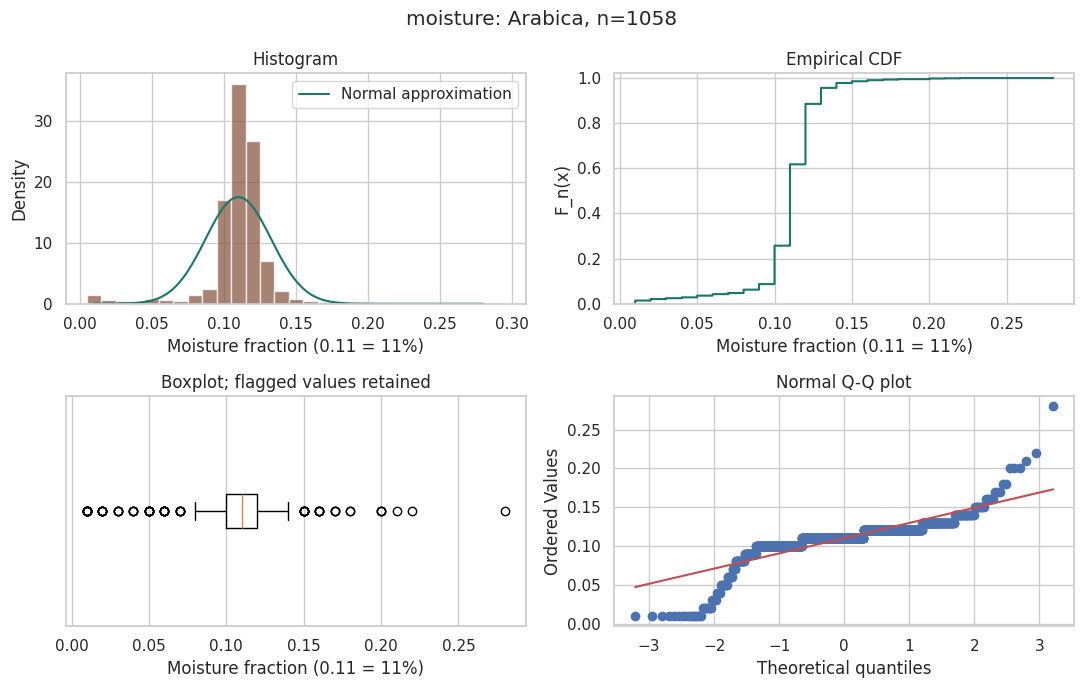

**Вывод по графикам влажности**

На гистограмме видим узкий пик около 11%. Центральная половина наблюдений лежит между **10,0 и 12,0%**; на CDF этому участку соответствует резкий подъём. Крупные ступени показывают, что одни и те же записанные значения встречаются много раз

Асимметрия равна **-1,11**: распределение сильнее смещено в сторону малой влажности. При этом редкие большие значения тоже есть: весь диапазон составляет 1,0–28,0%. Boxplot отмечает 74 наблюдения по правилу 1,5 IQR, но само это правило не устанавливает ошибку измерения, поэтому эти строки сохраняем

На Q–Q-графике видим выраженные отклонения от прямой на обоих концах и ступени в середине. Нормальная кривая плохо передаёт одновременно узкий центральный пик и крайние значения

In [5]:
x = data["moisture"].to_numpy()
q1, q3 = np.quantile(x, [0.25, 0.75])
iqr = q3 - q1
flagged = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)
summary = pd.Series({"n": len(x), "mean": x.mean(), "median": np.median(x), "variance_ddof1": x.var(ddof=1), "std_ddof1": x.std(ddof=1), "min": x.min(), "q1": q1, "q3": q3, "max": x.max(), "skewness": stats.skew(x, bias=False), "IQR_flags": flagged.sum()})
print(summary.round(5).to_string())

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].hist(x, bins=np.arange(x.min()-.005, x.max()+.015, .01), density=True, color="#8a5a44", alpha=0.75)
grid = np.linspace(x.min(), x.max(), 300)
axes[0, 0].plot(grid, stats.norm.pdf(grid, x.mean(), x.std(ddof=1)), color="#18766b", label="Normal approximation")
axes[0, 0].set(xlabel="Moisture fraction (0.11 = 11%)", ylabel="Density", title="Histogram")
axes[0, 0].legend()
axes[0, 1].step(np.sort(x), np.arange(1, len(x)+1) / len(x), where="post", color="#18766b")
axes[0, 1].set(xlabel="Moisture fraction (0.11 = 11%)", ylabel="F_n(x)", title="Empirical CDF", ylim=(0, 1.02))
axes[1, 0].boxplot(x, vert=False)
axes[1, 0].set(xlabel="Moisture fraction (0.11 = 11%)", title="Boxplot; flagged values retained", yticks=[])
stats.probplot(x, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Normal Q-Q plot")
fig.suptitle("moisture: Arabica, n=" + str(len(x)))
fig.tight_layout()
plt.show()

show_md(
    f"**Вывод по графикам влажности**\n\n"
    f"На гистограмме видим узкий пик около 11%. Центральная половина наблюдений лежит между "
    f"**{fmt(100*q1,1)} и {fmt(100*q3,1)}%**; на CDF этому участку соответствует резкий подъём. "
    f"Крупные ступени показывают, что одни и те же записанные значения встречаются много раз\n\n"
    f"Асимметрия равна **{fmt(stats.skew(x,bias=False),2)}**: распределение сильнее смещено в сторону малой влажности. "
    f"При этом редкие большие значения тоже есть: весь диапазон составляет "
    f"{fmt(100*x.min(),1)}–{fmt(100*x.max(),1)}%. Boxplot отмечает {int(flagged.sum())} наблюдения по правилу 1,5 IQR, "
    f"но само это правило не устанавливает ошибку измерения, поэтому эти строки сохраняем\n\n"
    "На Q–Q-графике видим выраженные отклонения от прямой на обоих концах и ступени в середине. "
    "Нормальная кривая плохо передаёт одновременно узкий центральный пик и крайние значения"
)


### Independence & Estimations

Рассчитываем среднее влажности и сравниваем два способа построения доверительного интервала: t-интервал и bootstrap

In [6]:
estimate = interval_table.loc["moisture"]
show_table(estimate.to_frame("estimate"))
show_md(f"Получили среднее **{fmt(estimate['mean'],5)}**. Приближённый 95% t-интервал: **[{fmt(estimate['t_low'],5)}; {fmt(estimate['t_high'],5)}]**. Bootstrap-интервал: **[{fmt(estimate['bootstrap_low'],5)}; {fmt(estimate['bootstrap_high'],5)}]**. Границы двух интервалов близки.")

,estimate
n,1058.00000
mean,0.11000
t_low,0.10862
t_high,0.11138
bootstrap_low,0.10864
bootstrap_high,0.11133


Получили среднее **0,11000**. Приближённый 95% t-интервал: **[0,10862; 0,11138]**. Bootstrap-интервал: **[0,10864; 0,11133]**. Границы двух интервалов близки.

## Random Variable 2/3 - Кислотность

### Description

Вторая величина - оценка кислотности кофе при дегустации. Нас интересуют её разброс, форма распределения и связь с остальными показателями

### EDA & Distribution

n                 1058.00000
mean                 7.52662
median               7.50000
variance_ddof1       0.09867
std_ddof1            0.31411
min                  6.08000
q1                   7.33000
q3                   7.75000
max                  8.75000
skewness             0.11533
IQR_flags           19.00000


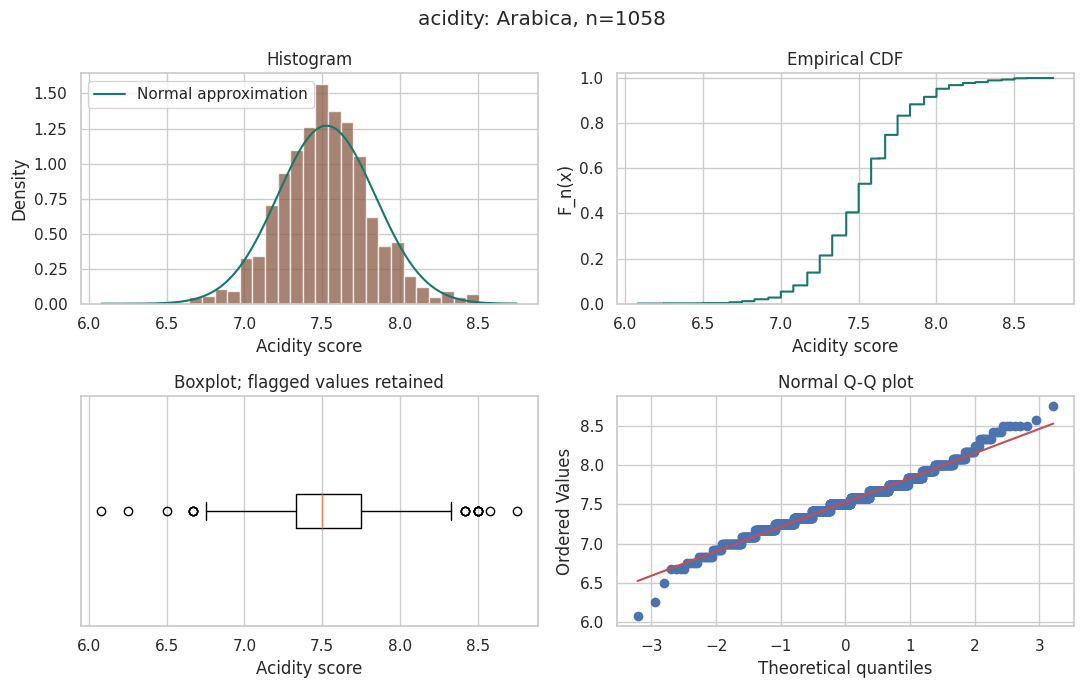

**Вывод по графикам кислотности**

Оценки сосредоточены около 7,5 балла: среднее равно **7,53**, медиана — **7,50**. Центральная половина наблюдений лежит между 7,33 и 7,75 балла. На CDF наиболее быстрый рост видим в этой области, а ступени соответствуют повторяющимся оценкам

Асимметрия небольшая: **0,12**. Гистограмма в целом похожа на колокол, но boxplot отмечает 19 крайних наблюдений с обеих сторон. На Q–Q-графике центральные точки близки к прямой, а на концах отклоняются от неё. Поэтому внешнее сходство с нормальной кривой ещё не означает согласия всего распределения с этой моделью

In [7]:
x = data["acidity"].to_numpy()
q1, q3 = np.quantile(x, [0.25, 0.75])
iqr = q3 - q1
flagged = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)
summary = pd.Series({"n": len(x), "mean": x.mean(), "median": np.median(x), "variance_ddof1": x.var(ddof=1), "std_ddof1": x.std(ddof=1), "min": x.min(), "q1": q1, "q3": q3, "max": x.max(), "skewness": stats.skew(x, bias=False), "IQR_flags": flagged.sum()})
print(summary.round(5).to_string())

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].hist(x, bins="fd", density=True, color="#8a5a44", alpha=0.75)
grid = np.linspace(x.min(), x.max(), 300)
axes[0, 0].plot(grid, stats.norm.pdf(grid, x.mean(), x.std(ddof=1)), color="#18766b", label="Normal approximation")
axes[0, 0].set(xlabel="Acidity score", ylabel="Density", title="Histogram")
axes[0, 0].legend()
axes[0, 1].step(np.sort(x), np.arange(1, len(x)+1) / len(x), where="post", color="#18766b")
axes[0, 1].set(xlabel="Acidity score", ylabel="F_n(x)", title="Empirical CDF", ylim=(0, 1.02))
axes[1, 0].boxplot(x, vert=False)
axes[1, 0].set(xlabel="Acidity score", title="Boxplot; flagged values retained", yticks=[])
stats.probplot(x, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Normal Q-Q plot")
fig.suptitle("acidity: Arabica, n=" + str(len(x)))
fig.tight_layout()
plt.show()

show_md(
    f"**Вывод по графикам кислотности**\n\n"
    f"Оценки сосредоточены около 7,5 балла: среднее равно **{fmt(x.mean(),2)}**, "
    f"медиана — **{fmt(np.median(x),2)}**. Центральная половина наблюдений лежит между "
    f"{fmt(q1,2)} и {fmt(q3,2)} балла. На CDF наиболее быстрый рост видим в этой области, "
    f"а ступени соответствуют повторяющимся оценкам\n\n"
    f"Асимметрия небольшая: **{fmt(stats.skew(x,bias=False),2)}**. Гистограмма в целом похожа на колокол, "
    f"но boxplot отмечает {int(flagged.sum())} крайних наблюдений с обеих сторон. "
    "На Q–Q-графике центральные точки близки к прямой, а на концах отклоняются от неё. "
    "Поэтому внешнее сходство с нормальной кривой ещё не означает согласия всего распределения с этой моделью"
)


### Independence & Estimations

Для кислотности также оцениваем среднее и строим t-интервал и bootstrap-интервал. Далее проверяем её связь с полнотой напитка

In [8]:
estimate = interval_table.loc["acidity"]
show_table(estimate.to_frame("estimate"))
show_md(f"Получили среднее **{fmt(estimate['mean'],5)}**. Приближённый 95% t-интервал: **[{fmt(estimate['t_low'],5)}; {fmt(estimate['t_high'],5)}]**. Bootstrap-интервал: **[{fmt(estimate['bootstrap_low'],5)}; {fmt(estimate['bootstrap_high'],5)}]**. Границы двух интервалов близки.")

,estimate
n,1058.00000
mean,7.52662
t_low,7.50767
t_high,7.54557
bootstrap_low,7.50814
bootstrap_high,7.54521


Получили среднее **7,52662**. Приближённый 95% t-интервал: **[7,50767; 7,54557]**. Bootstrap-интервал: **[7,50814; 7,54521]**. Границы двух интервалов близки.

## Random Variable 3/3 - Полнота напитка

### Description

Третья величина - оценка полноты напитка, то есть его текстуры и ощущения во рту. Рассматриваем, как эта оценка меняется между образцами и насколько согласуется с кислотностью

### EDA & Distribution

n                 1058.00000
mean                 7.50303
median               7.50000
variance_ddof1       0.08159
std_ddof1            0.28564
min                  6.33000
q1                   7.33000
q3                   7.67000
max                  8.58000
skewness             0.05974
IQR_flags           23.00000


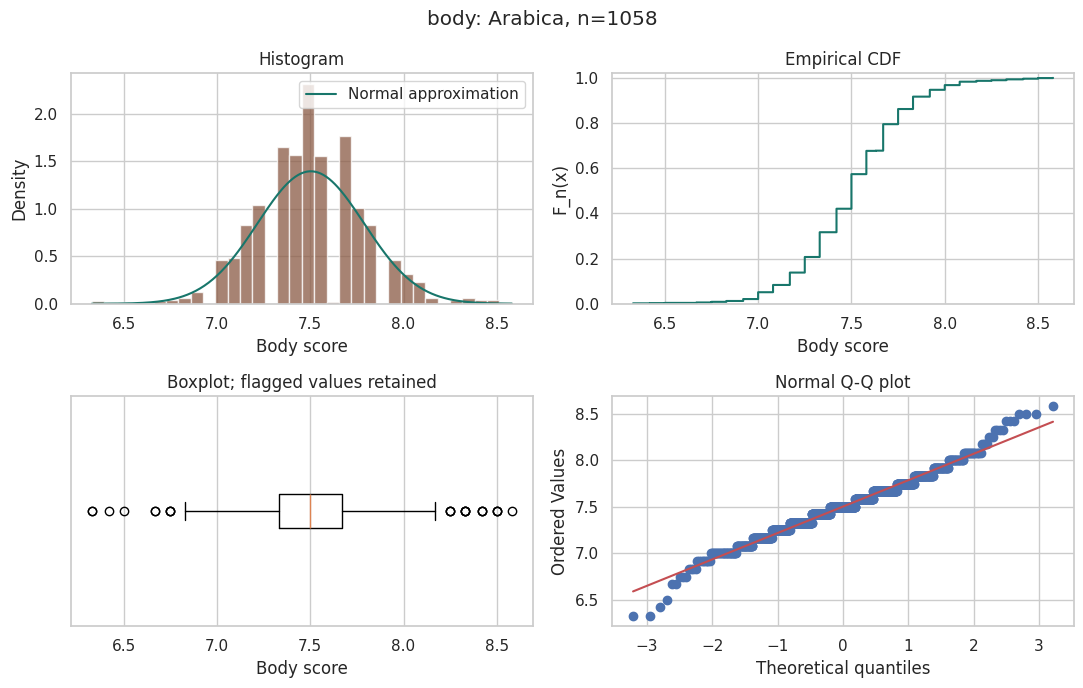

**Вывод по графикам полноты**

Среднее и медиана близки: **7,50** и **7,50** балла. Центральная половина наблюдений лежит между 7,33 и 7,67 балла. Разброс меньше, чем у кислотности: стандартные отклонения равны 0,286 и 0,314 балла соответственно

Распределение почти симметрично: асимметрия равна **0,06**. На гистограмме и CDF видим заметные скопления на отдельных оценках. Boxplot отмечает 23 крайних наблюдения, а концы Q–Q-графика расходятся с прямой. Нормальная кривая передаёт общий вид середины, но хуже описывает крайние значения и частоты отдельных баллов

In [9]:
x = data["body"].to_numpy()
q1, q3 = np.quantile(x, [0.25, 0.75])
iqr = q3 - q1
flagged = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)
summary = pd.Series({"n": len(x), "mean": x.mean(), "median": np.median(x), "variance_ddof1": x.var(ddof=1), "std_ddof1": x.std(ddof=1), "min": x.min(), "q1": q1, "q3": q3, "max": x.max(), "skewness": stats.skew(x, bias=False), "IQR_flags": flagged.sum()})
print(summary.round(5).to_string())

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].hist(x, bins="fd", density=True, color="#8a5a44", alpha=0.75)
grid = np.linspace(x.min(), x.max(), 300)
axes[0, 0].plot(grid, stats.norm.pdf(grid, x.mean(), x.std(ddof=1)), color="#18766b", label="Normal approximation")
axes[0, 0].set(xlabel="Body score", ylabel="Density", title="Histogram")
axes[0, 0].legend()
axes[0, 1].step(np.sort(x), np.arange(1, len(x)+1) / len(x), where="post", color="#18766b")
axes[0, 1].set(xlabel="Body score", ylabel="F_n(x)", title="Empirical CDF", ylim=(0, 1.02))
axes[1, 0].boxplot(x, vert=False)
axes[1, 0].set(xlabel="Body score", title="Boxplot; flagged values retained", yticks=[])
stats.probplot(x, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Normal Q-Q plot")
fig.suptitle("body: Arabica, n=" + str(len(x)))
fig.tight_layout()
plt.show()

show_md(
    f"**Вывод по графикам полноты**\n\n"
    f"Среднее и медиана близки: **{fmt(x.mean(),2)}** и **{fmt(np.median(x),2)}** балла. "
    f"Центральная половина наблюдений лежит между {fmt(q1,2)} и {fmt(q3,2)} балла. "
    f"Разброс меньше, чем у кислотности: стандартные отклонения равны "
    f"{fmt(x.std(ddof=1),3)} и {fmt(data['acidity'].std(ddof=1),3)} балла соответственно\n\n"
    f"Распределение почти симметрично: асимметрия равна **{fmt(stats.skew(x,bias=False),2)}**. "
    "На гистограмме и CDF видим заметные скопления на отдельных оценках. "
    f"Boxplot отмечает {int(flagged.sum())} крайних наблюдения, а концы Q–Q-графика расходятся с прямой. "
    "Нормальная кривая передаёт общий вид середины, но хуже описывает крайние значения и частоты отдельных баллов"
)


### Independence & Estimations

Рассчитываем среднее полноты напитка и доверительные интервалы теми же методами, что и для двух предыдущих величин

In [10]:
estimate = interval_table.loc["body"]
show_table(estimate.to_frame("estimate"))
show_md(f"Получили среднее **{fmt(estimate['mean'],5)}**. Приближённый 95% t-интервал: **[{fmt(estimate['t_low'],5)}; {fmt(estimate['t_high'],5)}]**. Bootstrap-интервал: **[{fmt(estimate['bootstrap_low'],5)}; {fmt(estimate['bootstrap_high'],5)}]**. Границы двух интервалов близки.")

,estimate
n,1058.00000
mean,7.50303
t_low,7.48580
t_high,7.52027
bootstrap_low,7.48606
bootstrap_high,7.52013


Получили среднее **7,50303**. Приближённый 95% t-интервал: **[7,48580; 7,52027]**. Bootstrap-интервал: **[7,48606; 7,52013]**. Границы двух интервалов близки.

### Нормализация и стандартизация

Чтобы сравнить показатели в общей шкале, используем два преобразования:

- min–max: $u_i=(x_i-x_{min})/(x_{max}-x_{min})$;
- z-score: $z_i=(x_i-\bar x)/s$, где стандартное отклонение рассчитано с `ddof=1`.

После min–max значения лежат в [0;1], а после стандартизации среднее равно 0 и стандартное отклонение - 1. Сохраняем исходную таблицу и записываем преобразованные значения отдельно. Эти преобразования меняют шкалу, сохраняя форму распределения. Для min–max особенно важны крайние значения, так как они задают границы диапазона

Параметры преобразований (исходные шкалы):
           min   max      mean  std_ddof1  range
moisture  0.01  0.28  0.110000   0.022794   0.27
acidity   6.08  8.75  7.526616   0.314114   2.67
body      6.33  8.58  7.503034   0.285637   2.25

Проверка диапазона, стандартизации и сохранения асимметрии:
          minmax_min  minmax_max  z_mean  z_std_ddof1  skew_original  skew_minmax  skew_zscore
moisture         0.0         1.0    -0.0          1.0      -1.109243    -1.109243    -1.109243
acidity          0.0         1.0     0.0          1.0       0.115326     0.115326     0.115326
body             0.0         1.0    -0.0          1.0       0.059739     0.059739     0.059739


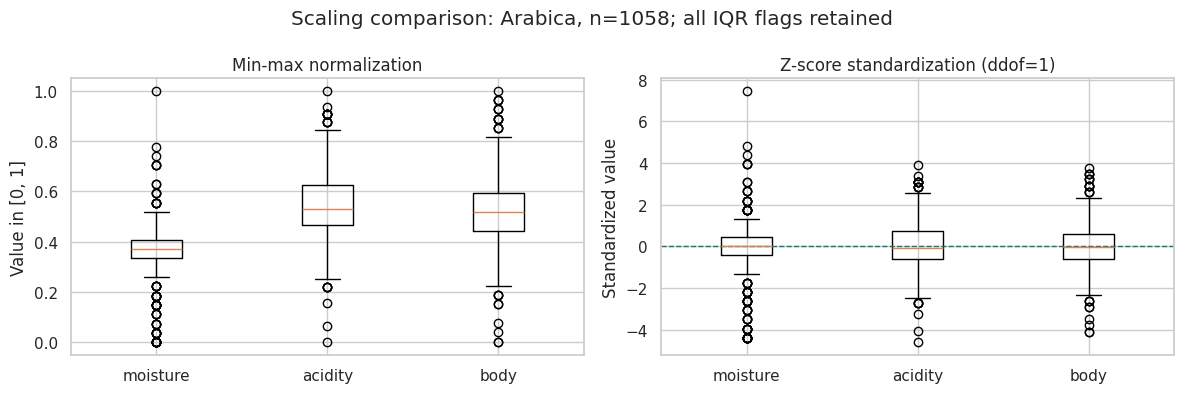

**Вывод по графикам преобразований**

После min–max все показатели лежат в диапазоне от 0 до 1. При этом коробка влажности выглядит узкой: её границы растягивают редкие крайние значения, а основная масса остаётся около 10–12%

После z-score средние равны 0, а стандартные отклонения — 1, поэтому сравниваем положение наблюдений относительно среднего каждого показателя. Крайние значения и различия формы сохранились: преобразование шкалы не сделало распределения нормальными и не устранило зависимость показателей. Для объяснения свойств кофе дальше используем исходные единицы

In [11]:
source_features = data[columns].copy()
scaling_parameters = pd.DataFrame({
    "min": source_features.min(),
    "max": source_features.max(),
    "mean": source_features.mean(),
    "std_ddof1": source_features.std(ddof=1),
})
scaling_parameters["range"] = scaling_parameters["max"] - scaling_parameters["min"]
assert scaling_parameters["range"].gt(0).all()
assert scaling_parameters["std_ddof1"].gt(0).all()
data_minmax = (source_features - scaling_parameters["min"]) / scaling_parameters["range"]
data_zscore = (source_features - scaling_parameters["mean"]) / scaling_parameters["std_ddof1"]

scaling_checks = pd.DataFrame({
    "minmax_min": data_minmax.min(),
    "minmax_max": data_minmax.max(),
    "z_mean": data_zscore.mean(),
    "z_std_ddof1": data_zscore.std(ddof=1),
    "skew_original": source_features.skew(),
    "skew_minmax": data_minmax.skew(),
    "skew_zscore": data_zscore.skew(),
})
print("Параметры преобразований (исходные шкалы):")
print(scaling_parameters.round(6).to_string())
print("\nПроверка диапазона, стандартизации и сохранения асимметрии:")
print(scaling_checks.round(6).to_string())
assert np.allclose(data_minmax.min(), 0)
assert np.allclose(data_minmax.max(), 1)
assert np.allclose(data_zscore.mean(), 0, atol=1e-12)
assert np.allclose(data_zscore.std(ddof=1), 1)
assert np.allclose(source_features.skew(), data_zscore.skew())
assert np.allclose(source_features.corr(), data_minmax.corr())
assert np.allclose(source_features.corr(), data_zscore.corr())
assert data[columns].equals(source_features)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, transformed, title, ylabel in [
    (axes[0], data_minmax, "Min-max normalization", "Value in [0, 1]"),
    (axes[1], data_zscore, "Z-score standardization (ddof=1)", "Standardized value"),
]:
    axis.boxplot([transformed[column].to_numpy() for column in columns])
    axis.set_xticks(np.arange(1, len(columns) + 1))
    axis.set_xticklabels(columns)
    axis.set(title=title, ylabel=ylabel)
axes[1].axhline(0, color="#18766b", linestyle="--", linewidth=1)
fig.suptitle(f"Scaling comparison: Arabica, n={len(data)}; all IQR flags retained")
fig.tight_layout()
plt.show()

show_md(
    "**Вывод по графикам преобразований**\n\n"
    "После min–max все показатели лежат в диапазоне от 0 до 1. При этом коробка влажности выглядит узкой: "
    "её границы растягивают редкие крайние значения, а основная масса остаётся около 10–12%\n\n"
    "После z-score средние равны 0, а стандартные отклонения - 1, поэтому сравниваем положение наблюдений "
    "относительно среднего каждого показателя. Крайние значения и различия формы сохранились: "
    "преобразование шкалы не сделало распределения нормальными и не устранило зависимость показателей. "
    "Для объяснения свойств кофе дальше используем исходные единицы"
)

## Критерий 6: математическая база распределений и их особенности

### Какое распределение описываем

Для начала описываем каждую величину с помощью эмпирического распределения, используя частоты значений в подготовленной таблице

Пусть $N$ - размер подготовленного набора, $I$ равновероятно выбирает номер строки: $P(I=i)=1/N$, а $X=x_I$ - значение одного показателя в этой строке

Уникальные значения обозначаем $a_1<\dots<a_K$, их количества - $c_1,\dots,c_K$. Тогда **функция вероятностей (PMF)** имеет вид

$$
p_j=P_{\mathrm{emp}}(X=a_j)=\frac{c_j}{N},
\qquad p_j>0,
\qquad \sum_{j=1}^{K}p_j=1
$$

Выбираем строки с одинаковой вероятностью, поэтому вероятность отдельного значения зависит от числа его повторений

Эмпирическая **функция распределения (CDF)**

$$
F_N(t)=P_{\mathrm{emp}}(X\le t)
=\sum_{a_j\le t}p_j
=\frac{1}{N}\sum_{i=1}^{N}\mathbf{1}\{x_i\le t\}
$$

Здесь $\mathbf{1}\{x_i\le t\}$ равна единице, если $x_i\le t$, и нулю в остальных случаях

Функция $F_N(t)$ не убывает, непрерывна справа и имеет скачок величины $p_j$ в точке $a_j$. Ниже минимума $F_N(t)=0$, начиная с максимума $F_N(t)=1$

Например, вероятность попадания в интервал рассчитываем так

$$
P_{\mathrm{emp}}(a<X\le b)=F_N(b)-F_N(a)
$$

В нашей таблице конечное число значений, поэтому эмпирическое распределение дискретно. Частоты описывают записанные значения напрямую. По их повторениям нельзя установить, получены ли они простым округлением или более сложной обработкой оценок

### Параметры и форма

По этим вероятностям рассчитываем математическое ожидание, дисперсию и центральные моменты

$$
\mu_{\mathrm{emp}}
=\sum_{j=1}^{K}a_jp_j
=\bar{x}
$$

$$
\sigma_{\mathrm{emp}}^2
=\sum_{j=1}^{K}(a_j-\mu_{\mathrm{emp}})^2p_j
=\frac{1}{N}\sum_{i=1}^{N}(x_i-\bar{x})^2
$$

Коэффициент асимметрии

$$
\gamma_1=
\frac{\mathbb{E}_{\mathrm{emp}}\left[(X-\mu_{\mathrm{emp}})^3\right]}
{\sigma_{\mathrm{emp}}^3}
$$

Эксцесс

$$
\gamma_2=
\frac{\mathbb{E}_{\mathrm{emp}}\left[(X-\mu_{\mathrm{emp}})^4\right]}
{\sigma_{\mathrm{emp}}^4}-3
$$

Для дисперсии эмпирического распределения делим сумму квадратов отклонений на $N$. Для несмещённой выборочной оценки дисперсии при независимых одинаково распределённых наблюдениях используем $N-1$

Асимметрию и эксцесс здесь считаем непосредственно по моментам распределения

Мода - любое значение с наибольшим $p_j$; мод может быть несколько

Квантиль уровня $q\in(0,1)$ определяется как

$$
Q(q)=\inf\{t:F_N(t)\ge q\}
$$

В таблицах EDA используем линейную интерполяцию pandas/NumPy для вычисления квартилей

По знаку асимметрии оцениваем направление перекоса распределения, а по эксцессу сравниваем четвёртый стандартизованный момент с нормальным законом. При выводах также учитываем графики и проверку согласия

### Нормальный закон как модель для сравнения

Для $Y\sim\mathcal{N}(\mu,\sigma^2)$, где $\sigma>0$, плотность имеет вид

$$
f_Y(y)=\frac{1}{\sigma\sqrt{2\pi}}
\exp\left[-\frac{(y-\mu)^2}{2\sigma^2}\right],
\qquad y\in\mathbb{R}
$$

Функция распределения

$$
F_Y(y)=\Phi\left(\frac{y-\mu}{\sigma}\right)
$$

Здесь $\Phi$ - функция распределения стандартного нормального закона

$$
\Phi(z)=\int_{-\infty}^{z}
\frac{e^{-u^2/2}}{\sqrt{2\pi}}\,du
$$

У нормального закона $\mathbb{E}(Y)=\mu$, $\operatorname{Var}(Y)=\sigma^2$. Он симметричен и одномодален, среднее, медиана и мода совпадают, асимметрия и эксцесс равны нулю. Область возможных значений — вся числовая прямая

$f_Y(y)$ - **плотность**, а не вероятность отдельного значения: $P(Y=y)=0$, вероятность интервала равна интегралу плотности

У дискретной модели выше вероятность наблюдаемого значения положительна, поэтому высоты PMF и непрерывной плотности не сравниваем как одинаковые величины

На гистограммах с нормировкой плотности добавляем нормальную кривую с $\mu=\bar{x}$ и $\sigma=s$ (`ddof=1`). На Q–Q-графике смотрим, насколько точки отклоняются от прямой

Далее подбираем параметры нормального и логистического распределений и проверяем их согласование с данными с учётом округления


moisture: пять наиболее частых значений
 value  count  probability      CDF
  0.11    381     0.360113 0.617202
  0.12    283     0.267486 0.884688
  0.10    180     0.170132 0.257089
  0.13     75     0.070888 0.955577
  0.09     26     0.024575 0.086957

acidity: пять наиболее частых значений
 value  count  probability      CDF
  7.50    134     0.126654 0.531191
  7.58    118     0.111531 0.642722
  7.67    110     0.103970 0.747637
  7.42    108     0.102079 0.404537
  7.33     94     0.088847 0.302457

body: пять наиболее частых значений
 value  count  probability      CDF
  7.50    162     0.153119 0.573724
  7.67    124     0.117202 0.794896
  7.33    116     0.109641 0.316635
  7.42    110     0.103970 0.420605
  7.58    109     0.103025 0.676749


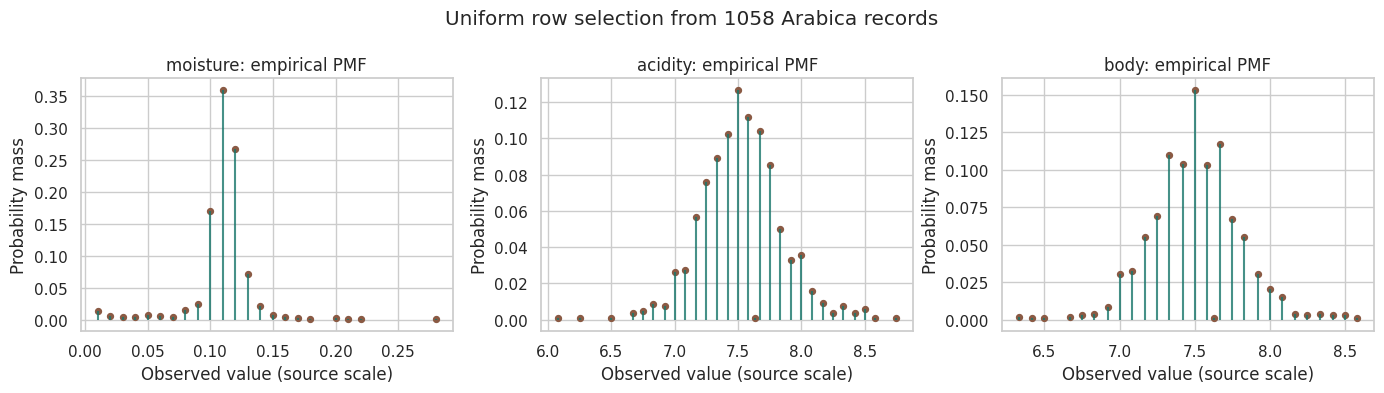


Математические характеристики эмпирических распределений:
             N  unique_values  support_min  support_max modes  mode_probability  mean_emp  variance_emp_ddof0  skewness_emp  excess_emp
variable                                                                                                                               
moisture  1058             22         0.01         0.28  0.11          0.360113  0.110000            0.000519     -1.107670   10.500643
acidity   1058             29         6.08         8.75   7.5          0.126654  7.526616            0.098574      0.115162    1.166210
body      1058             28         6.33         8.58   7.5          0.153119  7.503034            0.081511      0.059654    1.176584


**Вывод по графикам вероятностей**

Самый заметный пик у влажности: значение 0,11 встречается в **36,0%** строк. Для кислотности и полноты наиболее частая оценка — 7,5 балла, её доли равны 12,7% и 15,3%. Высота каждой линии показывает вероятность записанного значения при равновероятном выборе строки

У кислотности и полноты асимметрия близка к нулю, но эмпирический эксцесс положителен: 1,17 и 1,18. У влажности он заметно больше: 10,50. Это согласуется с заметной ролью крайних значений на предыдущих графиках

Таблицы значений, частот, вероятностей и CDF сохранены в `distribution_tables`. Для их построения не требуется предположение о том, как именно округляли или усредняли исходные измерения

In [12]:
distribution_tables = {}
distribution_math_rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, column in zip(axes, columns):
    counts = data[column].value_counts().sort_index()
    support = counts.index.to_numpy(dtype=float)
    probabilities = counts.to_numpy() / len(data)
    distribution_table = pd.DataFrame({
        "value": support, "count": counts.to_numpy(),
        "probability": probabilities, "CDF": probabilities.cumsum(),
    })
    distribution_tables[column] = distribution_table
    mean = np.sum(support * probabilities)
    variance = np.sum((support - mean)**2 * probabilities)
    skewness = np.sum((support - mean)**3 * probabilities) / variance**1.5
    excess = np.sum((support - mean)**4 * probabilities) / variance**2 - 3
    modes = support[counts.to_numpy() == counts.max()]
    distribution_math_rows.append({
        "variable": column, "N": len(data), "unique_values": len(support),
        "support_min": support.min(), "support_max": support.max(),
        "modes": ", ".join(f"{value:g}" for value in modes),
        "mode_probability": probabilities.max(),
        "mean_emp": mean, "variance_emp_ddof0": variance,
        "skewness_emp": skewness, "excess_emp": excess,
    })
    assert counts.sum() == len(data)
    assert np.isclose(probabilities.sum(), 1)
    assert np.all(np.diff(distribution_table["CDF"]) >= 0)
    assert np.isclose(distribution_table["CDF"].iloc[-1], 1)
    assert np.isclose(mean, data[column].mean())
    assert np.isclose(variance, data[column].var(ddof=0))
    axis.vlines(support, 0, probabilities, color="#18766b", alpha=.8)
    axis.scatter(support, probabilities, color="#8a5a44", s=18)
    axis.set(title=f"{column}: empirical PMF", xlabel="Observed value (source scale)", ylabel="Probability mass")
    print(f"\n{column}: пять наиболее частых значений")
    print(distribution_table.sort_values(["count", "value"], ascending=[False, True]).head(5).round(6).to_string(index=False))
fig.suptitle(f"Uniform row selection from {len(data)} Arabica records")
fig.tight_layout()
plt.show()
distribution_math_table = pd.DataFrame(distribution_math_rows).set_index("variable")
print("\nМатематические характеристики эмпирических распределений:")
print(distribution_math_table.round(6).to_string())

show_md(
    f"**Вывод по графикам вероятностей**\n\n"
    f"Самый заметный пик у влажности: значение 0,11 встречается в "
    f"**{fmt(100*distribution_math_table.loc['moisture','mode_probability'],1)}%** строк. "
    f"Для кислотности и полноты наиболее частая оценка - 7,5 балла, её доли равны "
    f"{fmt(100*distribution_math_table.loc['acidity','mode_probability'],1)}% и "
    f"{fmt(100*distribution_math_table.loc['body','mode_probability'],1)}%. "
    "Высота каждой линии показывает вероятность записанного значения при равновероятном выборе строки\n\n"
    f"У кислотности и полноты асимметрия близка к нулю, но эмпирический эксцесс положителен: "
    f"{fmt(distribution_math_table.loc['acidity','excess_emp'],2)} и "
    f"{fmt(distribution_math_table.loc['body','excess_emp'],2)}. "
    f"У влажности он заметно больше: {fmt(distribution_math_table.loc['moisture','excess_emp'],2)}. "
    "Это согласуется с заметной ролью крайних значений на предыдущих графиках\n\n"
)

### Подбор теоретических моделей и проверка согласия

Для каждого показателя сравниваем два семейства: нормальное и логистическое

Плотность логистического распределения:

$$
g(y;\mu,s)=
\frac{e^{-(y-\mu)/s}}
{s\left(1+e^{-(y-\mu)/s}\right)^2},
\qquad s>0
$$

Функция распределения:

$$
G(y)=\frac{1}{1+e^{-(y-\mu)/s}}
$$

Логистическое распределение симметрично, его параметры:

$$
\mathbb{E}(Y)=\mu,
\qquad
\operatorname{Var}(Y)=\frac{\pi^2s^2}{3},
\qquad
\gamma_2=1{,}2
$$

Выбрали логистическое распределение как симметричную альтернативу нормальному с большим четвёртым стандартизованным моментом. Оба семейства имеют неограниченную область возможных значений, поэтому рассматриваем их как приближения

**Допущение о записи:** для проверки задаём модель $X=Q_\delta(Y)$, где $Y$ имеет выбранное непрерывное распределение, а $Q_\delta$ округляет его до сетки с шагом $\delta=0{,}01$

Этот шаг соответствует разряду сотых в CSV, но не устанавливает точность измерения или фактический шаг выставления дегустационных баллов. Записанные оценки могли пройти дополнительное усреднение и обработку, порядок которых по этой таблице не восстанавливаем

Поэтому простое округление принимаем как наше приближение. В этой проверке оцениваем сочетание «распределение + способ записи», а не отдельно закон скрытой физической величины

Тогда вероятность записанного значения:

$$
P_\theta(X=a)=
G_\theta\left(a+\frac{\delta}{2}\right)
-
G_\theta\left(a-\frac{\delta}{2}\right)
$$

Здесь $G_\theta$ - функция распределения выбранного семейства, а $\theta$ — набор его параметров

Логарифмическое правдоподобие:

$$
\ell(\theta)=
\sum_{j=1}^{K}c_j\log P_\theta(X=a_j)
$$

Параметры подбираем по максимуму этого правдоподобия. Для сравнения моделей рассчитываем информационный критерий Акаике:

$$
\mathrm{AIC}=2k-2\ell(\hat{\theta}),
\qquad k=2
$$

Меньший AIC указывает на предпочтительную модель среди сравниваемых, а согласие с данными проверяем отдельно

Для каждой пары «показатель - семейство» формулируем гипотезы:

При предположении независимости и одинакового распределения строк проверяем:

- $H_0$: распределение записанных значений получается из выбранного семейства с неизвестными параметрами простым округлением до $0{,}01$
- $H_1$: распределение записанных значений не описывается этим сочетанием семейства и округления

Статистика $D$ — максимальное абсолютное расхождение эмпирической и модельной функций распределения, включая левые пределы скачков

Для получения $p$-значения используем параметрический бутстрэп:

1. Подгоняем модель по исходным данным и рассчитываем наблюдаемую статистику $D_{\mathrm{obs}}$
2. Генерируем из подогнанной модели выборку того же объёма
3. Округляем полученные значения и заново оцениваем параметры
4. Рассчитываем статистику $D^*$ для сгенерированной выборки и заново подогнанной модели
5. Повторяем процедуру 499 раз

Оценка $p$-значения:

$$
p_{\mathrm{MC}}=
\frac{
1+\sum_{b=1}^{499}
\mathbf{1}\{D_b^*\ge D_{\mathrm{obs}}\}
}{500}
$$

Для шести проверок применяем поправку Холма при $\alpha=0{,}05$

Это приближённая калибровка составной гипотезы с оценёнными параметрами. Минимальное возможное значение $p_{\mathrm{MC}}$ при таком числе повторений — $0{,}002$

При отклонении $H_0$ делаем вывод о несогласии именно с заданной моделью. Причиной могут быть форма распределения, неучтённая обработка оценок или нарушение предположения о независимости строк — эта проверка не разделяет их влияние

Для дальнейших экспериментов используем эмпирическое распределение, которое сохраняет наблюдаемые значения и их частоты без восстановления скрытого механизма получения баллов

loc     scale  log_likelihood           AIC  \
variable family                                                       
moisture norm      0.109999  0.022612    -2372.590488   4749.180977   
         logistic  0.111631  0.009450    -2159.066346   4322.132693   
acidity  norm      7.526616  0.313952    -5147.842654  10299.685308   
         logistic  7.522624  0.172937    -5131.980256  10267.960513   
body     norm      7.503034  0.285487    -5047.296855  10098.593709   
         logistic  7.501539  0.157535    -5032.176101  10068.352202   

                   CDF_distance   p_MC  latent_mass_outside_physical_scale  \
variable family                                                              
moisture norm          0.166607  0.002                            0.000001   
         logistic      0.080188  0.002                            0.000007   
acidity  norm          0.068959  0.002                            0.000000   
         logistic      0.056646  0.002                            0.000001   
body     norm          0.070977  0.002                            0.000000   
         logistic      0.069020  0.002                            0.000000   

                   p_Holm_6  reject_model  
variable family                            
moisture norm         0.012          True  
         logistic     0.012          True  
acidity  norm         0.012          True  
         logistic     0.012          True  
body     norm         0.012          True  
         logistic     0.012          True

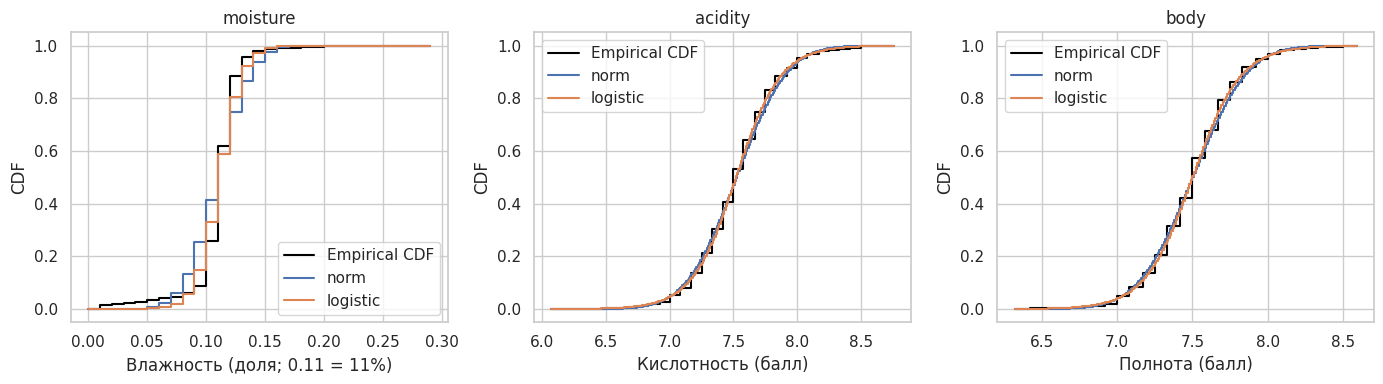

**Вывод по сравнению моделей**

Для влажности модельные CDF заметно расходятся с эмпирической около центрального скачка. Для кислотности и полноты общий ход кривых похож, но отдельные скачки наблюдаемых частот модели передают хуже. Внешней близости кривых недостаточно, чтобы принять модель

В таблице логистическая модель имеет меньший AIC для каждого показателя, однако это только выбор между двумя предложенными приближениями. После поправки Холма отвергаем **6 из 6** сочетаний семейства и простого округления до 0,01

Не делаем из этого вывод, что скрытые величины заведомо не могут иметь нормальное или логистическое распределение при другом механизме получения записанных оценок. Для экспериментов с повторными выборками оставляем эмпирическое распределение

In [13]:
"""Проверяем приближение: непрерывное распределение и простое округление до 0,01."""
import numpy as np
from scipy import stats, optimize

def rounded_fit(x, family, step=0.01):
    """Оцениваем параметры распределения по значениям, записанным на сетке."""
    x = np.asarray(x, dtype=float)
    support, counts = np.unique(x, return_counts=True)
    center, unit = x.mean(), x.std(ddof=0)
    dist = getattr(stats, family)
    loc0, scale0 = dist.fit(x)
    def negative_log_likelihood(theta):
        loc = center + unit * theta[0]
        scale = unit * np.exp(theta[1])
        lower = (support - step / 2 - loc) / scale
        upper = (support + step / 2 - loc) / scale
        probability = np.where(lower >= 0,
                               dist.sf(lower) - dist.sf(upper),
                               dist.cdf(upper) - dist.cdf(lower))
        return -np.dot(counts, np.log(np.maximum(probability, np.finfo(float).tiny)))
    start = [(loc0-center)/unit, np.log(scale0/unit)]
    result = optimize.minimize(negative_log_likelihood, start, method='L-BFGS-B',
                               bounds=[(-10,10),(-6,4)], options={'ftol':1e-10})
    if not result.success:
        result = optimize.minimize(negative_log_likelihood, start, method='Powell',
                                   bounds=[(-10,10),(-6,4)])
    if not result.success or not np.isfinite(result.fun):
        raise RuntimeError('Distribution fit did not converge: ' + result.message)
    loc = center + unit * result.x[0]
    scale = unit * np.exp(result.x[1])
    return float(loc), float(scale), float(-result.fun)

def rounded_cdf_distance(x, family, loc, scale, step=0.01):
    support, counts = np.unique(x, return_counts=True)
    right = np.cumsum(counts) / len(x)
    left = right - counts / len(x)
    dist = getattr(stats, family)
    model_right = dist.cdf((support + step/2 - loc)/scale)
    model_left = dist.cdf((support - step/2 - loc)/scale)
    return max(np.max(np.abs(right-model_right)), np.max(np.abs(left-model_left)))


fitted_model_rows = []
fitted_parameters = {}
model_rng = np.random.default_rng(SEED + 610)
model_repetitions = 499
for column in columns:
    values = data[column].to_numpy()
    for family in ["norm", "logistic"]:
        loc, scale, log_likelihood = rounded_fit(values, family)
        observed_D = rounded_cdf_distance(values, family, loc, scale)
        extreme = 0
        for _ in range(model_repetitions):
            latent = (model_rng.normal(loc, scale, len(values)) if family == "norm" else
                      model_rng.logistic(loc, scale, len(values)))
            simulated = np.round(latent, 2)
            sim_loc, sim_scale, _ = rounded_fit(simulated, family)
            extreme += rounded_cdf_distance(simulated, family, sim_loc, sim_scale) >= observed_D - 1e-12
        p_mc = (extreme+1)/(model_repetitions+1)
        lower, upper = (0,1) if column == "moisture" else (0,10)
        dist = getattr(stats, family)
        fitted_parameters[(column,family)] = (loc,scale)
        fitted_model_rows.append({"variable":column, "family":family, "loc":loc, "scale":scale,
            "log_likelihood":log_likelihood, "AIC":4-2*log_likelihood,
            "CDF_distance":observed_D, "p_MC":p_mc,
            "latent_mass_outside_physical_scale":dist.cdf((lower-loc)/scale)+dist.sf((upper-loc)/scale)})
fitted_model_table = pd.DataFrame(fitted_model_rows)
fitted_model_table["p_Holm_6"] = holm_adjust(fitted_model_table["p_MC"])
fitted_model_table["reject_model"] = fitted_model_table["p_Holm_6"] < ALPHA
show_table(fitted_model_table.set_index(["variable","family"]), 6)
fig, axes = plt.subplots(1,3,figsize=(14,4))
for axis, column in zip(axes, columns):
    values = data[column].to_numpy()
    grid = np.round(np.arange(values.min()-.01, values.max()+.015, .01),2)
    axis.step(grid, np.searchsorted(np.sort(values),grid,side="right")/len(values), where="post", color="black",label="Empirical CDF")
    for family in ["norm","logistic"]:
        loc,scale = fitted_parameters[(column,family)]
        axis.step(grid,getattr(stats,family).cdf((grid+.005-loc)/scale),where="post",label=family)
    axis.set(title=column,xlabel=labels[column],ylabel="CDF")
    axis.legend()
fig.tight_layout()
plt.show()
rejected_count = int(fitted_model_table["reject_model"].sum())
show_md(
    "**Вывод по сравнению моделей**\n\n"
    "Для влажности модельные CDF заметно расходятся с эмпирической около центрального скачка. "
    "Для кислотности и полноты общий ход кривых похож, но отдельные скачки наблюдаемых частот модели передают хуже. "
    "Внешней близости кривых недостаточно, чтобы принять модель\n\n"
    "В таблице логистическая модель имеет меньший AIC для каждого показателя, однако это только выбор "
    "между двумя предложенными приближениями. "
    f"После поправки Холма отвергаем **{rejected_count} из {len(fitted_model_table)}** сочетаний "
    "семейства и простого округления до 0,01\n\n"
    "Не делаем из этого вывод, что скрытые величины заведомо не могут иметь нормальное или логистическое распределение "
    "при другом механизме получения записанных оценок. Для экспериментов с повторными выборками "
    "оставляем эмпирическое распределение"
)

## Связи между показателями

Строим диаграммы рассеяния и рассчитываем коэффициенты Пирсона и Спирмена для трёх пар показателей. Первый характеризует линейную связь, второй - монотонную. Для трёх тестов каждого типа применяем поправку Холма

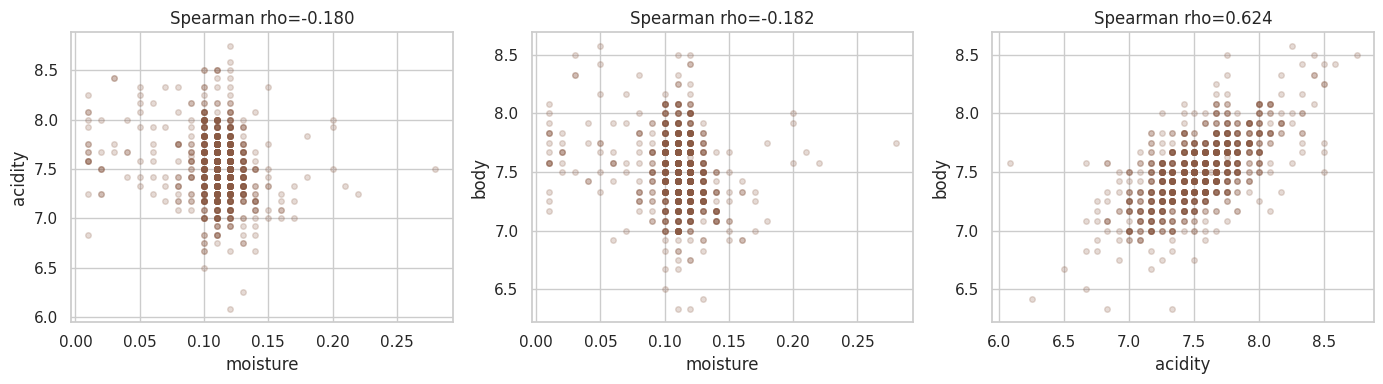

                    pearson_r   pearson_p  spearman_rho  spearman_p  pearson_p_holm  spearman_p_holm
pair                                                                                                
moisture / acidity    -0.1816  2.6889e-09      -0.18017  3.5944e-09      2.6889e-09       4.7173e-09
moisture / body      -0.18872  6.1319e-10      -0.18225  2.3587e-09      1.2264e-09       4.7173e-09
acidity / body        0.65442 2.3604e-130       0.62357 4.8388e-115     7.0812e-130      1.4516e-114


**Вывод по диаграммам рассеяния**

Самая заметная связь — между кислотностью и полнотой: облако точек вытянуто вверх, коэффициент Спирмена равен **0,624**. Образцы с большей оценкой кислотности обычно получают и большую оценку полноты, но разброс точек показывает, что соответствие не однозначное

Связи влажности с кислотностью и полнотой слабее и направлены вниз: -0,180 и -0,182. При большом числе наблюдений даже слабая связь может быть статистически значимой, поэтому учитываем величину коэффициента. Скопления точек на сетке связаны с повторяющимися записанными значениями; причинное влияние одного показателя на другой по этим диаграммам не устанавливаем

In [14]:
pairs = [("moisture", "acidity"), ("moisture", "body"), ("acidity", "body")]
correlation_rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, (first, second) in zip(axes, pairs):
    pearson = stats.pearsonr(data[first], data[second])
    spearman = stats.spearmanr(data[first], data[second])
    correlation_rows.append({"pair": first + " / " + second, "pearson_r": pearson.statistic, "pearson_p": pearson.pvalue, "spearman_rho": spearman.statistic, "spearman_p": spearman.pvalue})
    axis.scatter(data[first], data[second], s=16, alpha=0.22, color="#8a5a44")
    axis.set(xlabel=first, ylabel=second, title=f"Spearman rho={spearman.statistic:.3f}")
fig.tight_layout()
plt.show()
correlation_table = pd.DataFrame(correlation_rows).set_index("pair")
correlation_table["pearson_p_holm"] = holm_adjust(correlation_table["pearson_p"])
correlation_table["spearman_p_holm"] = holm_adjust(correlation_table["spearman_p"])
print(correlation_table.to_string(float_format=lambda value: f"{value:.5g}"))

show_md(
    "**Вывод по диаграммам рассеяния**\n\n"
    f"Самая заметная связь - между кислотностью и полнотой: облако точек вытянуто вверх, "
    f"коэффициент Спирмена равен **{fmt(correlation_table.loc['acidity / body','spearman_rho'],3)}**. "
    "Образцы с большей оценкой кислотности обычно получают и большую оценку полноты, "
    "но разброс точек показывает, что соответствие не однозначное\n\n"
    f"Связи влажности с кислотностью и полнотой слабее и направлены вниз: "
    f"{fmt(correlation_table.loc['moisture / acidity','spearman_rho'],3)} и "
    f"{fmt(correlation_table.loc['moisture / body','spearman_rho'],3)}. "
    "При большом числе наблюдений даже слабая связь может быть статистически значимой, "
    "поэтому учитываем величину коэффициента. Скопления точек на сетке связаны с повторяющимися записанными значениями; "
)


## Критерии 2 и 7: зависимость и проверка гипотезы

Проверяем связь кислотности и полноты: оба показателя получены при оценке одного образца кофе

Обозначаем кислотность через $A$, полноту через $B$ и формулируем гипотезы:

$$
H_0:\ A \text{ и } B \text{ независимы}
$$

$$
H_1:\ A \text{ и } B \text{ зависимы}
$$

Уровень значимости: $\alpha=0{,}05$

При независимости для любых множеств значений $U$ и $V$ выполняется:

$$
P(A\in U,\ B\in V)=P(A\in U)\,P(B\in V)
$$

Сначала сравниваем обе части равенства для событий $A\ge7{,}5$ и $B\ge7{,}5$ в эмпирическом распределении:

$$
P_{\mathrm{emp}}(A\ge7{,}5,\ B\ge7{,}5)
\quad \text{и} \quad
P_{\mathrm{emp}}(A\ge7{,}5)\,P_{\mathrm{emp}}(B\ge7{,}5)
$$

Затем проводим перестановочный тест со статистикой $|\rho_s|$, где $\rho_s$ — коэффициент ранговой корреляции Спирмена

Оставляем кислотность на месте, случайно переставляем оценки полноты между строками и заново рассчитываем корреляцию. При $H_0$ и обменности строк такие перестановки дают распределение статистики при независимости

Совпадающим значениям присваиваем усреднённые ранги. Всего выполняем 9999 перестановок и рассчитываем:

$$
p_{\mathrm{MC}}=
\frac{
1+\sum_{b=1}^{9999}
\mathbf{1}\left\{
|\rho_s^{(b)}|\ge|\rho_s^{\mathrm{obs}}|
\right\}
}{9999+1}
$$

Здесь $\rho_s^{\mathrm{obs}}$ — корреляция в исходных данных, а $\rho_s^{(b)}$ — корреляция после перестановки с номером $b$

Если $p_{\mathrm{MC}}<0{,}05$, отвергаем $H_0$

Дополнительно показываем поправку Бонферрони на три пары показателей:

$$
p_{\mathrm{Bonf}}=\min(1,\ 3p_{\mathrm{MC}})
$$

Нулевая корреляция сама по себе не доказывает независимость, поскольку коэффициент Спирмена прежде всего выявляет монотонную связь. Поэтому отсутствие значимого результата означало бы, что этим тестом зависимость не обнаружена

Описание метода:

- [SciPy: коэффициент Спирмена](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html)
- [SciPy: перестановочный тест](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html)

In [15]:
# пары оценок одного образца
criterion2_a = data["acidity"].to_numpy()
criterion2_b = data["body"].to_numpy()
criterion2_n = len(criterion2_a)

criterion2_event_a = criterion2_a >= 7.5
criterion2_event_b = criterion2_b >= 7.5
criterion2_pa = criterion2_event_a.mean()
criterion2_pb = criterion2_event_b.mean()
criterion2_pab = (criterion2_event_a & criterion2_event_b).mean()
print("Иллюстрация для эмпирического распределения:")
print(f"P(acidity >= 7.5) = {criterion2_pa:.6f}")
print(f"P(body >= 7.5) = {criterion2_pb:.6f}")
print(f"P(оба события) = {criterion2_pab:.6f}")
print(f"Произведение вероятностей = {criterion2_pa * criterion2_pb:.6f}")

# коэффициент Спирмена
criterion2_rank_a = stats.rankdata(criterion2_a, method="average")
criterion2_rank_b = stats.rankdata(criterion2_b, method="average")
criterion2_rank_a = criterion2_rank_a - criterion2_rank_a.mean()
criterion2_rank_b = criterion2_rank_b - criterion2_rank_b.mean()
criterion2_scale = np.linalg.norm(criterion2_rank_a) * np.linalg.norm(criterion2_rank_b)
criterion2_rho = np.dot(criterion2_rank_a, criterion2_rank_b) / criterion2_scale

criterion2_rng = np.random.default_rng(42)
criterion2_repetitions = 9999
criterion2_extreme = 0
for _ in range(criterion2_repetitions):
    criterion2_permuted = criterion2_rng.permutation(criterion2_rank_b)
    criterion2_rho_null = np.dot(criterion2_rank_a, criterion2_permuted) / criterion2_scale
    if abs(criterion2_rho_null) >= abs(criterion2_rho) - 1e-12:
        criterion2_extreme += 1
criterion2_p_mc = (criterion2_extreme + 1) / (criterion2_repetitions + 1)
criterion2_p_bonf = min(1.0, 3 * criterion2_p_mc)

print("\nПерестановочная проверка независимости:")
print(f"n = {criterion2_n}; Spearman rho = {criterion2_rho:.6f}")
print(f"Перестановок = {criterion2_repetitions}; не менее экстремальных = {criterion2_extreme}")
print(f"Monte Carlo p-value = {criterion2_p_mc:.6f}")
print(f"С поправкой Бонферрони на три пары = {criterion2_p_bonf:.6f}")
print("H0 независимости", "отвергается" if criterion2_p_bonf < 0.05 else "не отвергается", "при alpha = 0.05")

show_md(f"При α={ALPHA} **{'отвергаем' if criterion2_p_bonf<ALPHA else 'не отвергаем'} H0**. Получили ρs={fmt(criterion2_rho,4)}, p_MC={fmt(criterion2_p_mc,4)}; с поправкой на три пары - {fmt(criterion2_p_bonf,4)}. Вывод делаем при предположении обменности строк. Разрешение p_MC при 9999 перестановках составляет 0,0001")

Иллюстрация для эмпирического распределения:
P(acidity >= 7.5) = 0.595463
P(body >= 7.5) = 0.579395
P(оба события) = 0.443289
Произведение вероятностей = 0.345008

Перестановочная проверка независимости:
n = 1058; Spearman rho = 0.623569
Перестановок = 9999; не менее экстремальных = 0
Monte Carlo p-value = 0.000100
С поправкой Бонферрони на три пары = 0.000300
H0 независимости отвергается при alpha = 0.05


При α=0.05 **отвергаем H0**. Получили ρs=0,6236, p_MC=0,0001; с поправкой на три пары - 0,0003. Вывод делаем при предположении обменности строк. Разрешение p_MC при 9999 перестановках составляет 0,0001

### Проверка по странам и фермам

Проверяем, сколько строк относится к одним странам, фермам и организациям. Также ищем совпадения полного сочетания «страна - ферма - номер партии - дата оценки». Такие записи рассматриваем как кандидатов для проверки и автоматически не удаляем

Чтобы оценить устойчивость связи кислотности и полноты, используем два подхода:

1. Рассчитываем корреляции внутри стран с n≥20. Затем центрируем ранги внутри каждой страны и переставляем значения только между строками одной страны. Так проверяем связь после учёта межстрановых различий. Строки без страны в эту проверку не включаем
2. Проводим кластерный bootstrap по фермам. Для группировки используем страну и приведённое к одному виду название фермы. Пустые и сборные названия вроде `various` исключаем из этой проверки. На каждом повторении выбираем с возвращением K ферм и включаем все их строки. Всего делаем 1000 повторений и сравниваем результат с обычным bootstrap на том же поднаборе

Для перестановок внутри страны предполагаем обменность строк, а для кластерного bootstrap - независимость между фермами. При этом внутри фермы записи могут быть зависимыми. Неполные сведения об экспертах и партиях остаются ограничением этого анализа

In [16]:
def normalize_label(series):
    return series.astype("string").str.strip().str.lower().str.replace(r"\s+", " ", regex=True)

group_audit_rows = []
for field in ["country_of_origin","farm_name","owner","certification_body"]:
    labels_clean = normalize_label(data[field]).dropna()
    counts = labels_clean.value_counts()
    group_audit_rows.append({"field":field, "missing":int(data[field].isna().sum()),
        "distinct_labels":len(counts), "labels_with_multiple_rows":int(counts.gt(1).sum()),
        "largest_group":int(counts.max())})
group_audit = pd.DataFrame(group_audit_rows).set_index("field")
show_table(group_audit,0)
identity_fields = ["country_of_origin","farm_name","lot_number","grading_date"]
identity_complete = data.dropna(subset=identity_fields)
duplicate_identity_n = int(identity_complete.duplicated(identity_fields, keep=False).sum())
print("Строк с полным потенциальным ключом партии:",len(identity_complete),
      "; строк с совпадающим ключом:",duplicate_identity_n,"(кандидаты для проверки, не автоматические дубликаты)")

country_data = data.dropna(subset=["country_of_origin"]).reset_index(drop=True)
country_groups = list(country_data.groupby("country_of_origin",sort=True).indices.values())
within_country_rows = []
for country, subset in country_data.groupby("country_of_origin",sort=True):
    if len(subset)>=20:
        within_country_rows.append({"country":country,"n":len(subset),
            "rho":stats.spearmanr(subset["acidity"],subset["body"]).statistic})
within_country_table = pd.DataFrame(within_country_rows).set_index("country")
show_table(within_country_table.sort_values("n",ascending=False),4)
rank_a = stats.rankdata(country_data["acidity"].to_numpy()).astype(float)
rank_b = stats.rankdata(country_data["body"].to_numpy()).astype(float)
for positions in country_groups:
    rank_a[positions] -= rank_a[positions].mean()
    rank_b[positions] -= rank_b[positions].mean()
within_scale = np.linalg.norm(rank_a)*np.linalg.norm(rank_b)
within_rho = np.dot(rank_a,rank_b)/within_scale
within_rng = np.random.default_rng(SEED+270)
within_extreme = 0
within_repetitions = 1999
for _ in range(within_repetitions):
    permuted_b = rank_b.copy()
    for positions in country_groups:
        permuted_b[positions] = within_rng.permutation(rank_b[positions])
    within_extreme += abs(np.dot(rank_a,permuted_b)/within_scale) >= abs(within_rho)-1e-12
within_p = (within_extreme+1)/(within_repetitions+1)

farm_label = normalize_label(data["farm_name"])
country_label = normalize_label(data["country_of_origin"])
generic_pattern = r"^(?:various|varios|varias|several|multiple|mixed|unknown|none|n/?a|not specified|\d+)(?:$|\s)"
farm_usable = farm_label.notna() & country_label.notna() & farm_label.ne("") & ~farm_label.str.contains(generic_pattern,regex=True,na=False)
farm_data = data.loc[farm_usable].copy().reset_index(drop=True)
farm_data["farm_cluster"] = (country_label[farm_usable]+" | "+farm_label[farm_usable]).to_numpy()
farm_groups = list(farm_data.groupby("farm_cluster",sort=True).indices.values())
farm_values = farm_data[columns].to_numpy()
farm_rho = stats.spearmanr(farm_values[:,1],farm_values[:,2]).statistic
bootstrap_rng = np.random.default_rng(SEED+271)
farm_boot = np.empty((1000,4))
iid_farm_boot = np.empty((1000,4))
for repetition in range(1000):
    chosen = bootstrap_rng.integers(len(farm_groups),size=len(farm_groups))
    cluster_positions = np.concatenate([farm_groups[j] for j in chosen])
    iid_positions = bootstrap_rng.integers(len(farm_values),size=len(farm_values))
    for destination, positions in [(farm_boot,cluster_positions),(iid_farm_boot,iid_positions)]:
        values = farm_values[positions]
        destination[repetition,:3] = values.mean(axis=0)
        destination[repetition,3] = stats.spearmanr(values[:,1],values[:,2]).statistic
farm_cluster_ci = np.quantile(farm_boot,[.025,.975],axis=0)
farm_iid_ci = np.quantile(iid_farm_boot,[.025,.975],axis=0)
farm_bootstrap_table = pd.DataFrame({
    "point_estimate":np.r_[farm_values.mean(axis=0),farm_rho],
    "iid_low":farm_iid_ci[0],"iid_high":farm_iid_ci[1],
    "farm_cluster_low":farm_cluster_ci[0],"farm_cluster_high":farm_cluster_ci[1],
},index=columns+["acidity_body_rho"])
show_table(farm_bootstrap_table,5)
show_md(f"После центрирования рангов внутри стран получили статистику {fmt(within_rho,3)} и p_MC={fmt(within_p,4)} при n={len(country_data)}. В проверку по фермам вошли {len(farm_data)} строк и {len(farm_groups)} кластеров. Для этого поднабора получили ρs={fmt(farm_rho,3)} и 95% кластерный bootstrap-интервал [{fmt(farm_cluster_ci[0,3],3)}; {fmt(farm_cluster_ci[1,3],3)}]. Положительная связь сохраняется при обоих способах учёта группирования")

,missing,distinct_labels,labels_with_multiple_rows,largest_group
field,,,,
country_of_origin,1,33,25,222
farm_name,239,494,112,39
owner,6,278,121,155
certification_body,0,24,23,201


Строк с полным потенциальным ключом партии: 185 ; строк с совпадающим ключом: 6 (кандидаты для проверки, не автоматические дубликаты)


,n,rho
country,,
Mexico,222,0.5153
Guatemala,174,0.6505
Colombia,106,0.5235
Brazil,101,0.5205
Taiwan,57,0.7884
Honduras,52,0.6813
United States (Hawaii),46,0.2858
Costa Rica,40,0.5353
Ethiopia,39,0.6930


,point_estimate,iid_low,iid_high,farm_cluster_low,farm_cluster_high
moisture,0.11153,0.11008,0.11307,0.10974,0.11314
acidity,7.52918,7.50891,7.55136,7.50088,7.55679
body,7.48884,7.47054,7.50922,7.46369,7.51496
acidity_body_rho,0.65332,0.60532,0.69493,0.60493,0.69921


После центрирования рангов внутри стран получили статистику 0,570 и p_MC=0,0005 при n=1057. В проверку по фермам вошли 753 строк и 489 кластеров. Для этого поднабора получили ρs=0,653 и 95% кластерный bootstrap-интервал [0,605; 0,699]. Положительная связь сохраняется при обоих способах учёта группирования

## Критерий 3: эмпирическая состоятельность оценок

Оценка $\widehat{\theta}_n$ состоятельна, если для любого $\varepsilon>0$:

$$
P\left(
|\widehat{\theta}_n-\theta|>\varepsilon
\right)\longrightarrow 0
\qquad \text{при } n\to\infty
$$

Проверяем **выборочное среднее** $\bar{X}_n$ как оценку математического ожидания и **исправленную выборочную дисперсию** $S_n^2$ как оценку дисперсии для каждого из трёх показателей

Хотим проверить, уменьшается ли ошибка этих оценок при увеличении объёма выборки

### Модель эксперимента

1058 подготовленных строк задают эмпирическое распределение: при каждом извлечении независимо выбираем строку с возвращением, вероятность выбора каждой строки равна $1/1058$

Известные параметры этой модели — среднее полного набора $\mu_{\mathrm{emp}}$ и его дисперсия $\sigma_{\mathrm{emp}}^2$ с делителем 1058 (`ddof=0`)

В повторных выборках оцениваем дисперсию с делителем $n-1$ (`ddof=1`). Выборки с возвращением могут содержать больше 1058 наблюдений, но не добавляют новых реальных данных

Для каждого объёма:

$$
n\in\{20,\ 50,\ 100,\ 250,\ 500,\ 1000,\ 5000\}
$$

получаем **1000 повторных выборок**

Для обеих оценок рассчитываем:

- Смещение - среднюю ошибку оценки по повторениям
- RMSE - корень из средней квадратичной ошибки по повторениям
- Долю повторений, в которых абсолютная ошибка превышает заданный порог
- Нормированный RMSE для сопоставления разных шкал

Обозначим число повторений через $R=1000$, а оценку в повторении $b$ — через $\widehat{\theta}_n^{(b)}$

Смещение оцениваем так:

$$
\widehat{\operatorname{Bias}}_n=
\frac{1}{R}\sum_{b=1}^{R}
\left(\widehat{\theta}_n^{(b)}-\theta_{\mathrm{emp}}\right)
$$

RMSE рассчитываем так:

$$
\widehat{\operatorname{RMSE}}_n=
\sqrt{
\frac{1}{R}\sum_{b=1}^{R}
\left(\widehat{\theta}_n^{(b)}-\theta_{\mathrm{emp}}\right)^2
}
$$

Долю превышений порога рассчитываем так:

$$
\widehat{p}_n=
\frac{1}{R}\sum_{b=1}^{R}
\mathbf{1}\left\{
\left|\widehat{\theta}_n^{(b)}-\theta_{\mathrm{emp}}\right|
>\varepsilon
\right\}
$$

Пороги фиксированы при всех $n$:

$$
\varepsilon_\mu=0{,}25\,\sigma_{\mathrm{emp}},
\qquad
\varepsilon_v=0{,}25\,\sigma_{\mathrm{emp}}^2
$$

Это позволяет проследить, как часто оценка заметно отклоняется от известного параметра при увеличении объёма выборки

Для нормированного RMSE ошибку среднего делим на $\sigma_{\mathrm{emp}}$, а ошибку оценки дисперсии - на $\sigma_{\mathrm{emp}}^2$

### Теоретическая опора

Для независимых одинаково распределённых наблюдений с конечной дисперсией выборочное среднее состоятельно по закону больших чисел

У выбранного эмпирического распределения существуют все моменты. Для среднего:

$$
\operatorname{MSE}(\bar{X}_n)=
\frac{\sigma_{\mathrm{emp}}^2}{n}
\longrightarrow 0
$$

Для исправленной выборочной дисперсии при $n>1$:

$$
\operatorname{MSE}(S_n^2)=
\frac{1}{n}
\left(
\mu_{4,\mathrm{emp}}
-\frac{n-3}{n-1}\sigma_{\mathrm{emp}}^4
\right)
\longrightarrow 0
$$

Здесь $\mu_{4,\mathrm{emp}}$ — четвёртый центральный момент эмпирического распределения:

$$
\mu_{4,\mathrm{emp}}=
\mathbb{E}_{\mathrm{emp}}
\left[(X-\mu_{\mathrm{emp}})^4\right]
$$

Обе оценки в этой модели несмещённые, поэтому их MSE равен их дисперсии

По неравенству Чебышёва:

$$
P\left(
|\widehat{\theta}_n-\theta_{\mathrm{emp}}|>\varepsilon
\right)
\le
\frac{\operatorname{MSE}(\widehat{\theta}_n)}{\varepsilon^2}
\longrightarrow 0
$$

Пунктир на графиках показывает теоретический RMSE этой модели

В эксперименте задаём независимость повторным отбором с возвращением и исследуем поведение оценок для эмпирического распределения

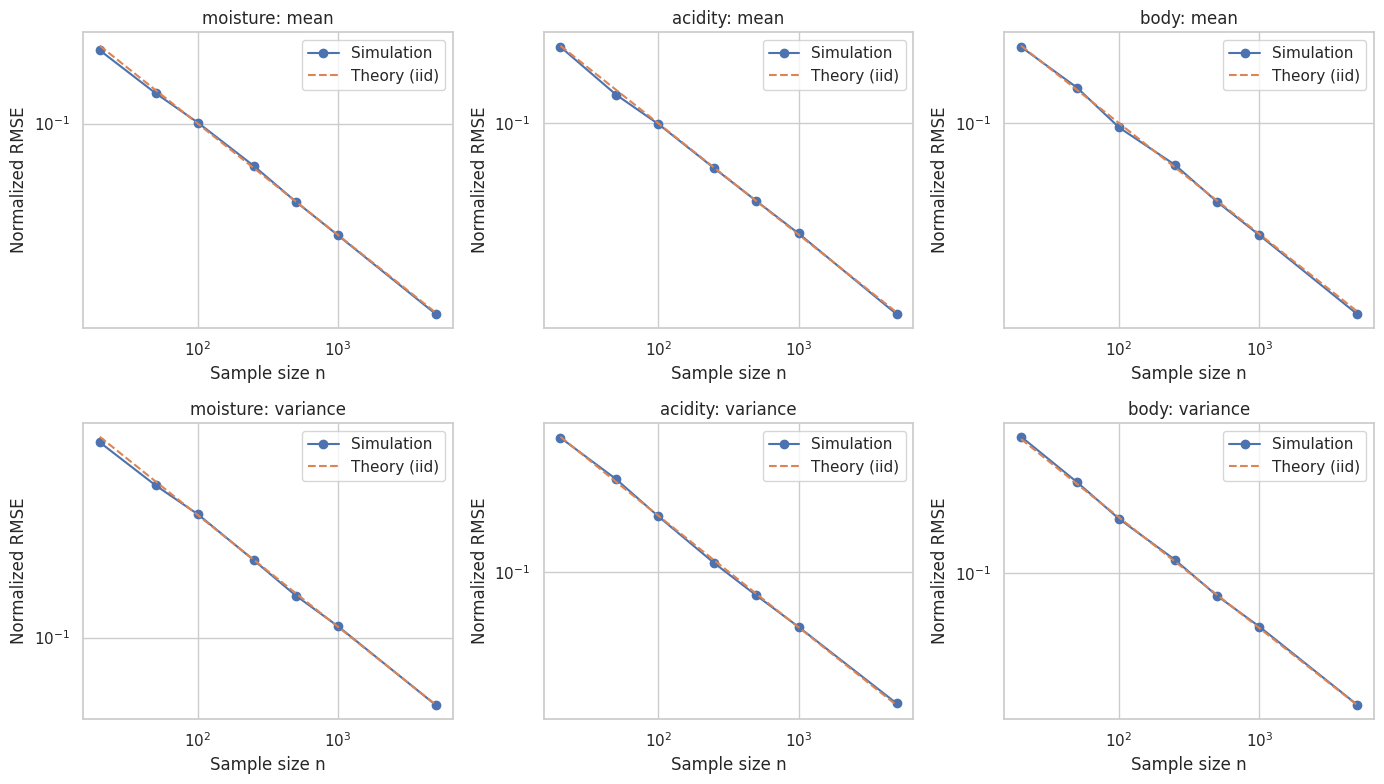

Повторений для каждого объёма: 1000
Средние: нормировка на sigma_emp; дисперсии: на variance_emp.
variable estimator    n   target      bias     RMSE  normalized_RMSE  epsilon  P_error_gt_epsilon
moisture      mean   20 0.110000  0.000081 0.004860         0.213297 0.005696               0.208
moisture  variance   20 0.000519 -0.000025 0.000389         0.749543 0.000130               0.775
moisture      mean   50 0.110000 -0.000063 0.003120         0.136949 0.005696               0.073
moisture  variance   50 0.000519  0.000000 0.000250         0.480974 0.000130               0.607
moisture      mean  100 0.110000 -0.000033 0.002304         0.101105 0.005696               0.020
moisture  variance  100 0.000519  0.000006 0.000185         0.357135 0.000130               0.476
moisture      mean  250 0.110000  0.000001 0.001474         0.064698 0.005696               0.000
moisture  variance  250 0.000519  0.000005 0.000116         0.222711 0.000130               0.263
moisture      mean  

RMSE_small_n  RMSE_large_n  P_large_error_small_n  \
variable estimator                                                      
moisture mean           0.004860      0.000318                  0.208   
         variance       0.000389      0.000026                  0.775   
acidity  mean           0.069362      0.004356                  0.243   
         variance       0.039479      0.002526                  0.518   
body     mean           0.063040      0.003925                  0.244   
         variance       0.033825      0.002063                  0.550   

                    P_large_error_large_n  
variable estimator                         
moisture mean                         0.0  
         variance                     0.0  
acidity  mean                         0.0  
         variance                     0.0  
body     mean                         0.0  
         variance                     0.0

**Вывод по графикам состоятельности**

Во всех шести панелях ошибка уменьшается с ростом n, а результаты повторных выборок близки к теоретическим пунктирным кривым. Для среднего скорость снижения RMSE соответствует зависимости от обратного квадратного корня из n

Для дисперсии влажности нормированная ошибка больше, чем для дисперсий дегустационных баллов. Это согласуется с большим четвёртым стандартизованным моментом влажности: её оценка дисперсии сильнее зависит от попадания крайних наблюдений в выборку

Полученные кривые иллюстрируют состоятельность среднего и исправленной дисперсии в выбранной iid-модели. Выборки до 5000 наблюдений получаем с возвращением из исходного набора. Нулевая наблюдаемая частота больших ошибок означает, что в 1000 повторениях такие ошибки не встретились

In [17]:
sizes = np.array([20, 50, 100, 250, 500, 1000, 5000])
repetitions = 1000
simulation_rng = np.random.default_rng(SEED)
simulation_rows = []
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for column_index, column in enumerate(columns):
    values = data[column].to_numpy()
    mean_target = values.mean()
    variance_target = values.var(ddof=0)
    sigma = np.sqrt(variance_target)
    fourth_moment = np.mean((values - mean_target)**4)
    for size in sizes:
        samples = simulation_rng.choice(values, size=(repetitions, size), replace=True)
        estimates_by_kind = {
            "mean": samples.mean(axis=1),
            "variance": samples.var(axis=1, ddof=1),
        }
        for estimator, estimates in estimates_by_kind.items():
            target = mean_target if estimator == "mean" else variance_target
            scale = sigma if estimator == "mean" else variance_target
            epsilon = 0.25 * scale
            errors = estimates - target
            theory_mse = (variance_target / size if estimator == "mean" else
                          (fourth_moment - (size - 3) / (size - 1) * variance_target**2) / size)
            simulation_rows.append({
                "variable": column, "estimator": estimator, "n": size,
                "target": target, "bias": errors.mean(),
                "RMSE": np.sqrt(np.mean(errors**2)),
                "normalized_RMSE": np.sqrt(np.mean(errors**2)) / scale,
                "theory_normalized_RMSE": np.sqrt(theory_mse) / scale,
                "epsilon": epsilon,
                "P_error_gt_epsilon": np.mean(np.abs(errors) > epsilon),
            })
    variable_results = pd.DataFrame(simulation_rows)
    for row_index, estimator in enumerate(["mean", "variance"]):
        subset = variable_results.loc[
            variable_results["variable"].eq(column) & variable_results["estimator"].eq(estimator)
        ]
        axis = axes[row_index, column_index]
        axis.loglog(subset["n"], subset["normalized_RMSE"], "o-", label="Simulation")
        axis.loglog(subset["n"], subset["theory_normalized_RMSE"], "--", label="Theory (iid)")
        axis.set(xlabel="Sample size n", ylabel="Normalized RMSE", title=f"{column}: {estimator}")
        axis.legend()
fig.tight_layout()
plt.show()
simulation_table = pd.DataFrame(simulation_rows)
print(f"Повторений для каждого объёма: {repetitions}")
print("Средние: нормировка на sigma_emp; дисперсии: на variance_emp.")
print(simulation_table.drop(columns=["theory_normalized_RMSE"]).round(6).to_string(index=False))

summary_rows = []
for column in columns:
    for estimator in ["mean","variance"]:
        subset = simulation_table.loc[simulation_table["variable"].eq(column)&simulation_table["estimator"].eq(estimator)]
        first,last = subset.iloc[0],subset.iloc[-1]
        summary_rows.append({"variable":column,"estimator":estimator,
            "RMSE_small_n":first["RMSE"],"RMSE_large_n":last["RMSE"],
            "P_large_error_small_n":first["P_error_gt_epsilon"],"P_large_error_large_n":last["P_error_gt_epsilon"]})
consistency_summary = pd.DataFrame(summary_rows).set_index(["variable","estimator"])
show_table(consistency_summary,6)
show_md(
    "**Вывод по графикам состоятельности**\n\n"
    "Во всех шести панелях ошибка уменьшается с ростом n, а результаты повторных выборок близки "
    "к теоретическим пунктирным кривым. Для среднего скорость снижения RMSE соответствует зависимости "
    "от обратного квадратного корня из n\n\n"
    "Для дисперсии влажности нормированная ошибка больше, чем для дисперсий дегустационных баллов. "
    "Это согласуется с большим четвёртым стандартизованным моментом влажности: её оценка дисперсии "
    "сильнее зависит от попадания крайних наблюдений в выборку\n\n"
    "Полученные кривые иллюстрируют состоятельность среднего и исправленной дисперсии в выбранной iid-модели. "
    "Выборки до 5000 наблюдений получаем с возвращением из исходного набора. "
    "Нулевая наблюдаемая частота больших ошибок означает, что в 1000 повторениях такие ошибки не встретились"
)

## Критерий 5: генеральная совокупность и два способа отбора

В этом разделе принимаем **1058 подготовленных записей Arabica** за конечную генеральную совокупность. Из неё берём меньшие выборки и сравниваем их статистики с известными параметрами всей таблицы

Рассчитываем объём по выбранной точности и используем одинаковое $n=300$ для двух способов отбора:

- **С возвращением:** при каждом из 300 извлечений любая строка имеет вероятность $1/N$, одна строка может попасть несколько раз. Повторно выбранные строки сохраняем
- **Без возвращения:** выбираем 300 разных строк, каждое подмножество такого размера равновероятно, вероятность включения каждой строки - $n/N$. Извлечения зависимы из-за запрета повторов

Отбираем целые строки, сохраняя сочетания `moisture`, `acidity` и `body`

### Сравнение статистик и погрешности

Рассчитываем среднее, медиану, дисперсию, стандартное отклонение, квартили и диапазон для совокупности и обеих выборок. Для среднего и дисперсии показываем ошибки относительно известных параметров

Среднее конечной совокупности:

$$
\mu_N=\frac{1}{N}\sum_{i=1}^{N}X_i
$$

Различаем две записи дисперсии конечной совокупности:

$$
\sigma_N^2=
\frac{1}{N}\sum_{i=1}^{N}(X_i-\mu_N)^2
$$

$$
S_N^2=
\frac{1}{N-1}\sum_{i=1}^{N}(X_i-\mu_N)^2
$$

При отборе с возвращением выборочная дисперсия $s^2$ (`ddof=1`) несмещённо оценивает $\sigma_N^2$

Без возвращения она несмещённо оценивает $S_N^2$, поэтому для сопоставления с одним параметром $\sigma_N^2$ используем:

$$
\widehat{\sigma}_N^2=\frac{N-1}{N}s^2
$$

В таблице приводим и обычное $s^2$, и приведённую к общей цели оценку

Обозначаем отбор с возвращением через WR, без возвращения — через WOR

Точная стандартная ошибка среднего при известной совокупности:

$$
\mathrm{SE}_{\mathrm{WR}}=
\frac{\sigma_N}{\sqrt{n}}
$$

$$
\mathrm{SE}_{\mathrm{WOR}}=
\frac{\sigma_N}{\sqrt{n}}
\sqrt{\frac{N-n}{N-1}}
$$

Для построения интервалов используем выборочные оценки стандартной ошибки:

$$
\widehat{\mathrm{SE}}_{\mathrm{WR}}=
\frac{s}{\sqrt{n}}
$$

$$
\widehat{\mathrm{SE}}_{\mathrm{WOR}}=
\frac{s}{\sqrt{n}}\sqrt{1-\frac{n}{N}}
$$

Строим приближённые 95% доверительные интервалы:

$$
\bar{x}\pm1{,}96\,\widehat{\mathrm{SE}}
$$

Проверяем, попало ли в них известное $\mu_N$. Используем нормальное приближение для распределения среднего и строим отдельный интервал для каждого показателя

Дополнительно повторяем обе схемы по **1000 раз при том же рассчитанном $n$** и сравниваем:

- Смещение и RMSE выборочного среднего
- Теоретическую стандартную ошибку среднего
- RMSE оценки дисперсии относительно $\sigma_N^2$
- Долю интервалов, покрывших $\mu_N$

Так сравниваем точность двух способов отбора по повторным выборкам

### Почему выбран такой размер

Ориентиры половины ширины 95% интервала:

- Для влажности - $0{,}003$ доли, то есть **0,3 %**
- Для кислотности и полноты — $0{,}04$ балла для каждого показателя

Обозначаем требуемую половину ширины интервала через $d$. Поскольку вся таблица известна, в формулы можем подставить её дисперсии

Для отбора с возвращением:

$$
n_{\mathrm{WR}}\ge
\frac{z_{0{,}975}^2\sigma_N^2}{d^2}
$$

Для отбора без возвращения:

$$
n_{\mathrm{WOR}}\ge
\frac{N z_{0{,}975}^2\sigma_N^2}
{d^2(N-1)+z_{0{,}975}^2\sigma_N^2}
$$

Здесь $z_{0{,}975}\approx1{,}96$ - квантиль стандартного нормального распределения

Берём максимум требуемых объёмов по трём показателям для WR и округляем **вверх до ближайшей сотни**. Получаем $n=300$ и используем этот объём для обеих схем

Это расчёт по нормальному приближению, фактическое покрытие дополнительно проверяем моделированием.

,target_half_width,minimum_n_WR,minimum_n_WOR
moisture,0.003,222,184
acidity,0.040,237,194
body,0.040,196,166


Конечная генеральная совокупность: N=1058; n=300 (28.4% N)

Схемы отбора:
                     draws  unique_rows  repeated_draws
design                                                 
with replacement       300          263              37
without replacement    300          300               0

Известные статистики генеральной совокупности:
             N      mean  median  variance_N  variance_N_minus_1     std_N    q1    q3   min   max
moisture  1058  0.110000    0.11    0.000519            0.000520  0.022784  0.10  0.12  0.01  0.28
acidity   1058  7.526616    7.50    0.098574            0.098667  0.313965  7.33  7.75  6.08  8.75
body      1058  7.503034    7.50    0.081511            0.081588  0.285502  7.33  7.67  6.33  8.58

Статистики отдельных выборок и ошибки относительно генеральной совокупности:


mean  median  s2_ddof1  \
design              variable                               
with replacement    moisture  0.109533    0.11  0.000556   
                    acidity   7.518733    7.50  0.096912   
                    body      7.504067    7.50  0.076369   
without replacement moisture  0.108800    0.11  0.000719   
                    acidity   7.501467    7.50  0.090507   
                    body      7.505733    7.50  0.064518   

                              variance_estimate_for_N  std_ddof1    q1    q3  \
design              variable                                                   
with replacement    moisture                 0.000556   0.023586  0.10  0.12   
                    acidity                  0.096912   0.311307  7.33  7.67   
                    body                     0.076369   0.276349  7.33  7.67   
without replacement moisture                 0.000718   0.026813  0.10  0.12   
                    acidity                  0.090421   0.300844  7.25  7.67   
                    body                     0.064457   0.254003  7.33  7.67   

                               min   max  
design              variable              
with replacement    moisture  0.01  0.22  
                    acidity   6.67  8.50  
                    body      6.33  8.58  
without replacement moisture  0.01  0.28  
                    acidity   6.67  8.50  
                    body      6.92  8.58

mean_error  variance_error  SE_estimate  \
design              variable                                            
with replacement    moisture   -0.000467        0.000037     0.001362   
                    acidity    -0.007883       -0.001662     0.017973   
                    body        0.001033       -0.005143     0.015955   
without replacement moisture   -0.001200        0.000199     0.001310   
                    acidity    -0.025150       -0.008153     0.014702   
                    body        0.002699       -0.017055     0.012413   

                              CI95_low  CI95_high  covers_population_mean  
design              variable                                               
with replacement    moisture  0.106864   0.112202                    True  
                    acidity   7.483506   7.553960                    True  
                    body      7.472795   7.535338                    True  
without replacement moisture  0.106232   0.111368                    True  
                    acidity   7.472652   7.530282                    True  
                    body      7.481405   7.530062                    True


Сравнение схем по 1000 повторениям (n=300):
             design variable  mean_bias  mean_RMSE  mean_SE_theory  variance_bias  variance_RMSE  CI95_coverage
   with replacement moisture  -0.000014   0.001323        0.001315       0.000003       0.000110          0.944
   with replacement  acidity  -0.000736   0.018391        0.018127      -0.000070       0.009830          0.945
   with replacement     body  -0.000217   0.016694        0.016483      -0.000009       0.008547          0.947
without replacement moisture  -0.000002   0.001099        0.001114      -0.000000       0.000091          0.947
without replacement  acidity  -0.000427   0.015130        0.015350       0.000019       0.008323          0.958
without replacement     body  -0.000164   0.013827        0.013959      -0.000248       0.006864          0.959

Точное отношение SE без возвращения / SE с возвращением: 0.8468


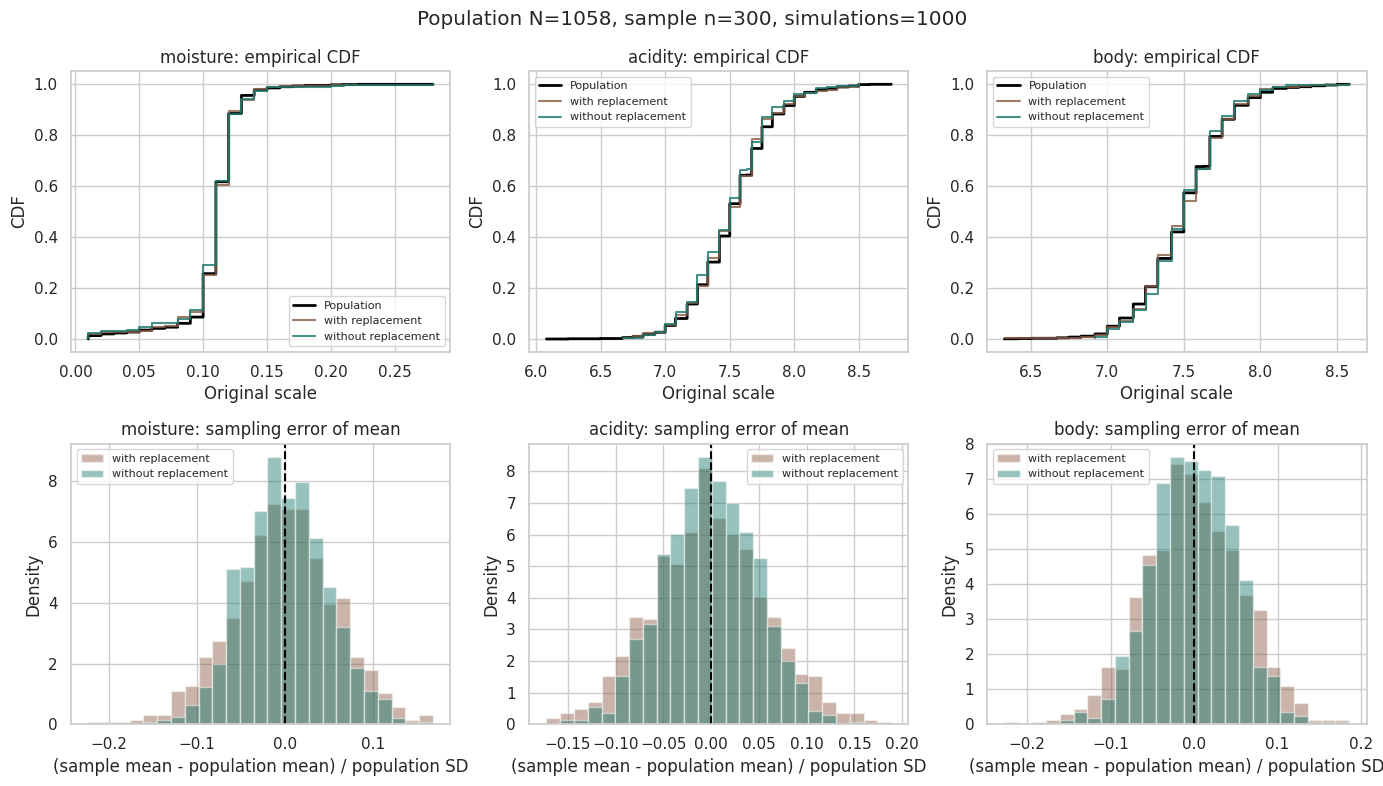

По расчёту точности выбрали **n=300 при N=1058**. Отношение стандартных ошибок без возвращения и с возвращением равно 0,847. Таким образом, отбор без возвращения уменьшает теоретическую стандартную ошибку на 15,3%. В 1000 повторениях интервалы покрыли средние генеральной совокупности в 94,4–95,9% случаев. Для оценки параметров этой конечной таблицы предпочитаем отбор без возвращения

**Что показывают графики отбора**

В верхнем ряду CDF обеих отдельных выборок в целом повторяют форму распределения полной таблицы, но на отдельных участках отличаются от неё. Это ожидаемый разброс при отборе части строк

В нижнем ряду ошибки средних по повторным выборкам сосредоточены около нуля. У отбора без возвращения распределения ошибок уже, что согласуется с меньшими RMSE в таблице и поправкой на конечную совокупность. Это преимущество по повторным отборам: одна конкретная выборка без возвращения всё равно может дать большую ошибку, чем одна выборка с возвращением

In [18]:
population = data[columns].copy()
population_n = len(population)
precision_targets = pd.Series({"moisture":.003,"acidity":.04,"body":.04})
planning_variance = population.var(ddof=0)
planning_z = stats.norm.ppf(.975)
planning_a = planning_z**2 * planning_variance / precision_targets**2
sample_size_plan = pd.DataFrame({"target_half_width":precision_targets,
    "minimum_n_WR":np.ceil(planning_a).astype(int),
    "minimum_n_WOR":np.ceil(population_n*planning_a/(population_n-1+planning_a)).astype(int)})
sample_n = int(np.ceil(sample_size_plan["minimum_n_WR"].max()/100)*100)
show_table(sample_size_plan,4)
assert 1 < sample_n < population_n
sampling_designs = [("with replacement", True), ("without replacement", False)]
sampling_rng = np.random.default_rng(SEED + 500)
sample_positions = {
    label: sampling_rng.choice(population_n, size=sample_n, replace=replace)
    for label, replace in sampling_designs
}
samples_by_design = {
    label: population.iloc[positions].copy()
    for label, positions in sample_positions.items()
}
sampling_design_table = pd.DataFrame([
    {"design": label, "draws": sample_n, "unique_rows": len(np.unique(positions)),
     "repeated_draws": sample_n - len(np.unique(positions))}
    for label, positions in sample_positions.items()
]).set_index("design")
assert sampling_design_table.loc["without replacement", "unique_rows"] == sample_n
population_stats = pd.DataFrame({
    "N": population_n, "mean": population.mean(), "median": population.median(),
    "variance_N": population.var(ddof=0), "variance_N_minus_1": population.var(ddof=1),
    "std_N": population.std(ddof=0), "q1": population.quantile(.25),
    "q3": population.quantile(.75), "min": population.min(), "max": population.max(),
})
sampling_comparison_rows = []
for label, replace in sampling_designs:
    sample = samples_by_design[label]
    for column in columns:
        values = sample[column].to_numpy()
        target_mean = population_stats.loc[column, "mean"]
        target_variance = population_stats.loc[column, "variance_N"]
        s2 = values.var(ddof=1)
        variance_estimate = s2 if replace else (population_n - 1) / population_n * s2
        correction = 1 if replace else np.sqrt(1 - sample_n / population_n)
        se_estimate = np.sqrt(s2 / sample_n) * correction
        low, high = values.mean() + np.array([-1, 1]) * stats.norm.ppf(.975) * se_estimate
        sampling_comparison_rows.append({
            "design": label, "variable": column, "n": len(values),
            "mean": values.mean(), "median": np.median(values), "s2_ddof1": s2,
            "variance_estimate_for_N": variance_estimate, "std_ddof1": np.sqrt(s2),
            "q1": np.quantile(values, .25), "q3": np.quantile(values, .75),
            "min": values.min(), "max": values.max(),
            "mean_error": values.mean() - target_mean,
            "variance_error": variance_estimate - target_variance,
            "SE_estimate": se_estimate, "CI95_low": low, "CI95_high": high,
            "covers_population_mean": bool(low <= target_mean <= high),
        })
sampling_comparison = pd.DataFrame(sampling_comparison_rows)
print(f"Конечная генеральная совокупность: N={population_n}; n={sample_n} ({sample_n/population_n:.1%} N)")
print("\nСхемы отбора:")
print(sampling_design_table.to_string())
print("\nИзвестные статистики генеральной совокупности:")
print(population_stats.round(6).to_string())
print("\nСтатистики отдельных выборок и ошибки относительно генеральной совокупности:")
show_table(sampling_comparison.set_index(["design","variable"])[["mean","median","s2_ddof1","variance_estimate_for_N","std_ddof1","q1","q3","min","max"]],6)
show_table(sampling_comparison.set_index(["design","variable"])[["mean_error","variance_error","SE_estimate","CI95_low","CI95_high","covers_population_mean"]],6)

# Сравниваем два способа отбора при одинаковом объёме выборки
sampling_repetitions = 1000
sampling_simulation_rng = np.random.default_rng(SEED + 501)
population_values = population.to_numpy()
population_mean = population_values.mean(axis=0)
population_variance = population_values.var(axis=0, ddof=0)
sampling_simulation_rows = []
sampling_mean_draws = {}
for label, replace in sampling_designs:
    means = np.empty((sampling_repetitions, len(columns)))
    variance_estimates = np.empty_like(means)
    covers = np.empty_like(means, dtype=bool)
    for repetition in range(sampling_repetitions):
        positions = sampling_simulation_rng.choice(population_n, size=sample_n, replace=replace)
        selected = population_values[positions]
        means[repetition] = selected.mean(axis=0)
        s2 = selected.var(axis=0, ddof=1)
        variance_estimates[repetition] = s2 if replace else (population_n - 1)/population_n*s2
        correction = 1 if replace else np.sqrt(1 - sample_n/population_n)
        half_width = stats.norm.ppf(.975) * np.sqrt(s2/sample_n) * correction
        covers[repetition] = np.abs(means[repetition] - population_mean) <= half_width
    sampling_mean_draws[label] = means
    exact_correction = 1 if replace else np.sqrt((population_n-sample_n)/(population_n-1))
    exact_se = np.sqrt(population_variance/sample_n) * exact_correction
    for j, column in enumerate(columns):
        errors = means[:, j] - population_mean[j]
        sampling_simulation_rows.append({
            "design": label, "variable": column,
            "mean_bias": errors.mean(), "mean_RMSE": np.sqrt(np.mean(errors**2)),
            "mean_SE_theory": exact_se[j],
            "variance_bias": (variance_estimates[:, j] - population_variance[j]).mean(),
            "variance_RMSE": np.sqrt(np.mean((variance_estimates[:, j] - population_variance[j])**2)),
            "CI95_coverage": covers[:, j].mean(),
        })
sampling_simulation = pd.DataFrame(sampling_simulation_rows)
print(f"\nСравнение схем по {sampling_repetitions} повторениям (n={sample_n}):")
print(sampling_simulation.round(6).to_string(index=False))
sampling_se_ratio = np.sqrt((population_n - sample_n)/(population_n - 1))
print(f"\nТочное отношение SE без возвращения / SE с возвращением: {sampling_se_ratio:.4f}")

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
colors = {"with replacement": "#8a5a44", "without replacement": "#18766b"}
for j, column in enumerate(columns):
    values = population[column].to_numpy()
    sorted_values = np.sort(values)
    axes[0, j].step(sorted_values, np.arange(1, population_n+1)/population_n,
                    where="post", color="black", linewidth=2, label="Population")
    for label, _ in sampling_designs:
        sorted_sample = np.sort(samples_by_design[label][column].to_numpy())
        axes[0, j].step(sorted_sample, np.arange(1, sample_n+1)/sample_n,
                        where="post", color=colors[label], alpha=.8, label=label)
    axes[0, j].set(title=column + ": empirical CDF", xlabel="Original scale", ylabel="CDF")
    axes[0, j].legend(fontsize=8)
    standardized_errors = {
        label: (sampling_mean_draws[label][:, j] - values.mean())/values.std(ddof=0)
        for label, _ in sampling_designs
    }
    bins = np.histogram_bin_edges(np.concatenate(list(standardized_errors.values())), bins=25)
    for label, errors in standardized_errors.items():
        axes[1, j].hist(errors, bins=bins, density=True, alpha=.45, color=colors[label], label=label)
    axes[1, j].axvline(0, color="black", linestyle="--")
    axes[1, j].set(title=column + ": sampling error of mean", xlabel="(sample mean - population mean) / population SD", ylabel="Density")
    axes[1, j].legend(fontsize=8)
fig.suptitle(f"Population N={population_n}, sample n={sample_n}, simulations={sampling_repetitions}")
fig.tight_layout()
plt.show()

show_md(f"По расчёту точности выбрали **n={sample_n} при N={population_n}**. Отношение стандартных ошибок без возвращения и с возвращением равно {fmt(sampling_se_ratio,3)}. Таким образом, отбор без возвращения уменьшает теоретическую стандартную ошибку на {fmt(100*(1-sampling_se_ratio),1)}%. В {sampling_repetitions} повторениях интервалы покрыли средние генеральной совокупности в {fmt(100*sampling_simulation['CI95_coverage'].min(),1)}–{fmt(100*sampling_simulation['CI95_coverage'].max(),1)}% случаев. Для оценки параметров этой конечной таблицы предпочитаем отбор без возвращения")

show_md(
    "**Что показывают графики отбора**\n\n"
    "В верхнем ряду CDF обеих отдельных выборок в целом повторяют форму распределения полной таблицы, "
    "но на отдельных участках отличаются от неё. Это ожидаемый разброс при отборе части строк\n\n"
    "В нижнем ряду ошибки средних по повторным выборкам сосредоточены около нуля. "
    "У отбора без возвращения распределения ошибок уже, что согласуется с меньшими RMSE в таблице "
    "и поправкой на конечную совокупность. Это преимущество по повторным отборам: "
    "одна конкретная выборка без возвращения всё равно может дать большую ошибку, чем одна выборка с возвращением"
)


## Lab resume

Основные результаты анализа.

In [19]:
show_md(f"Для основного анализа оставили {len(data)} записей Arabica из {len(raw)} строк исходного файла. Средняя влажность составила **{fmt(100*data['moisture'].mean(),2)}%**, кислотность - **{fmt(data['acidity'].mean(),4)}** балла, полнота - **{fmt(data['body'].mean(),4)}** балла")
show_md(f"Выявили положительную связь кислотности и полноты: **ρs={fmt(criterion2_rho,3)}**, p_MC={fmt(criterion2_p_mc,4)}. Она также сохранилась при проверках по странам и фермам")
show_md(f"Проверили нормальную и логистическую модели с допущением о простом округлении до 0,01 для трёх показателей. После поправки Холма отвергнуто **{int(fitted_model_table['reject_model'].sum())} из {len(fitted_model_table)}** моделей. Это результат для выбранного способа описания записанных значений, фактический механизм усреднения оценок по CSV не установлен. В экспериментах с выборками использовали эмпирические распределения. Показали уменьшение ошибки оценок с ростом n и сравнили два способа отбора выборки объёмом {sample_n} из {population_n} записей")
show_md("Свои выводы отношу к подготовленному набору Arabica. На результаты могут влиять исключение нулевой влажности, состав оценённых образцов и общие условия дегустации. Для интервалов использовали указанные в работе предположения о независимости и группировании наблюдений")

Для основного анализа оставили 1058 записей Arabica из 1339 строк исходного файла. Средняя влажность составила **11,00%**, кислотность - **7,5266** балла, полнота - **7,5030** балла

Выявили положительную связь кислотности и полноты: **ρs=0,624**, p_MC=0,0001. Она также сохранилась при проверках по странам и фермам

Проверили нормальную и логистическую модели с допущением о простом округлении до 0,01 для трёх показателей. После поправки Холма отвергнуто **6 из 6** моделей. Это результат для выбранного способа описания записанных значений; фактический механизм усреднения оценок по CSV не установлен. В экспериментах с выборками использовали эмпирические распределения. Показали уменьшение ошибки оценок с ростом n и сравнили два способа отбора выборки объёмом 300 из 1058 записей

Свои выводы отношу к подготовленному набору Arabica. На результаты могут влиять исключение нулевой влажности, состав оценённых образцов и общие условия дегустации. Для интервалов использовали указанные в работе предположения о независимости и группировании наблюдений

### Участники и cat_mark_table


In [20]:
team_table = pd.DataFrame(TEAM)
team_table["notebook_link"] = NOTEBOOK_URL
team_table["comment"] = team_table["name"] + " / " + team_table["github"]
cat_mark_table = team_table[["cat_id","notebook_link","coeff","comment"]]
show_table(cat_mark_table)
if team_table[["cat_id","coeff"]].isna().any().any():
    show_md("Для завершения таблицы участников нам нужно заполнить `cat_id` и `coeff` в `TEAM`.")

,cat_id,notebook_link,coeff,comment
0,None,https://github.com/Mironiks007/fifty-shades-of...,None,Петров Мирон / Mironiks007
1,None,https://github.com/Mironiks007/fifty-shades-of...,None,Каплунова Анна / kaplunovaania


Для завершения таблицы участников нам нужно заполнить `cat_id` и `coeff` в `TEAM`.

### Источники

- [TidyTuesday: таблица, словарь и цепочка очистки](https://github.com/rfordatascience/tidytuesday/tree/main/data/2020/2020-07-07)
- [Первичный код: перевод влажности из процентов в долю](https://github.com/jldbc/coffee-quality-database/blob/master/clean_coffee_data.R)
- [University of Hawai‘i: измерение влажности кофе](https://www.ctahr.hawaii.edu/oc/freepubs/pdf/EN-3.pdf)
- [SciPy: перестановки пар](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html)
- [Coffee Quality Database](https://github.com/jldbc/coffee-quality-database)
- [SciPy: коэффициент Спирмена](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html)

Версии библиотек вывожу в начале работы. Для повторных выборок и перестановок задаём фиксированные seed.